# Bước B1 - Sequential Forecast LSTM có Q của BiasCast + 3 thay đổi, 3 hạt giống (111, 222, 333) trên Kaggle T4:
##   (1) best_model.pt là epoch có NSE trung vị validation cao nhất (fork research e794d7c, test/test_best_model.py);
##   (2) qmean quá khứ theo mm/ngày (area_gov) như nhãn, thay m³/s của tác giả;
##   (3) thêm qmax quá khứ (mm/ngày) vào pha hindcast.
 Bài: Konold và cs., HESS 30:5067-5096 (2026). Dữ liệu Zenodo 17119635 (CC BY-NC 4.0), config tác giả Zenodo 17292895
      - đã lưu thành Kaggle Dataset "lamah-ce-ext" (Workspace/01_Download/01_LamaHCEExt_Download/01_LamaHCEExt_Download.py).
# Kế hoạch: Document/01_Plan/03_Pipeline.md Mục 7 (dòng B1), 9.1 (commit fork), 9.5 (định dạng dự báo).
 Mỗi hạt giống một tệp và một notebook Kaggle cùng tên: "01_B1_LamaHCEExt_Train_Seed111", "..._Seed222", "..._Seed333" -
 ba tệp giống hệt nhau, chỉ khác dòng RUN_SEED ở Phần 1 (một lần huấn luyện + đánh giá test từng epoch tối đa khoảng 6,8 giờ,
 ba lần không vừa một phiên 12 giờ - như A4). So sánh với A4 ở notebook CPU "02_B1_LamaHCEExt_Compare".
 Cài đặt mỗi notebook: Accelerator = GPU T4 x2 (dùng 1), Internet = On, Persistence = Files only,
 Environment = Pin to original environment, Add Input => lamah-ce-ext. Phiên tương tác: mỗi Phần một cell, chạy lần lượt.
 Dán nguyên tệp vào notebook rồi Save & Run All, không sửa dòng nào; Output chính thức (b1_runs/, b1_output/) lấy từ bản lưu đó.

# MỤC LỤC
   Phần 1 - Cài fork e794d7c, chạy kiểm thử lưu mô hình tốt nhất, kiểm môi trường
   Phần 2 - Tìm dữ liệu, danh sách lưu vực, config tác giả của run SeqLSTM có Q
   Phần 3 - Dựng thư mục dữ liệu có cột qmean_mmd, qmax_mmd
   Phần 4 - Tạo config cho hạt giống RUN_SEED, đếm mẫu huấn luyện
   Phần 5 - Huấn luyện hạt giống RUN_SEED
   Phần 6 - Đánh giá test và validation, kiểm best_model.pt là epoch NSE validation cao nhất
   Phần 7 - NSE test từng epoch (chỉ theo dõi)
   Phần 8 - Ghi môi trường, danh mục tệp, dọn thư mục dữ liệu tạm (NPZ dựng ở notebook so sánh, như A4)

# Phần 1 - Cài fork e794d7c, chạy kiểm thử lưu mô hình tốt nhất, kiểm môi trường
 Cài đúng commit e794d7c của nhánh research (dda45fc của bước A + sửa lỗi lưu mô hình tốt nhất; 03_Pipeline.md Mục 9.1).
 pip install git+... không cài thư mục test/ => tải riêng test/test_best_model.py của cùng commit (git fetch --depth 1),
 đặt vào thư mục tạm ngoài mã nguồn rồi chạy pytest => kiểm thử chạy trên gói vừa cài, không phải bản mã khác.
 Kiểm thêm basetrainer.py đã cài trùng từng byte với basetrainer.py của commit.
 In 3 bảng (thư viện, môi trường, điều kiện). tensorboard bắt buộc vì training/logger.py dòng 8 nạp SummaryWriter khi import.
 Phần 1-5 raise khi chưa đạt để Save & Run All dừng ngay, không tốn giờ GPU cho các Phần sau.

In [1]:
# %% Phần 1 - Cài fork e794d7c, chạy kiểm thử lưu mô hình tốt nhất, kiểm môi trường
# Cài đúng commit e794d7c của nhánh research (dda45fc của bước A + sửa lỗi lưu mô hình tốt nhất; 03_Pipeline.md Mục 9.1).
# pip install git+... không cài thư mục test/ => tải riêng test/test_best_model.py của cùng commit (git fetch --depth 1),
# đặt vào thư mục tạm ngoài mã nguồn rồi chạy pytest => kiểm thử chạy trên gói vừa cài, không phải bản mã khác.
# Kiểm thêm basetrainer.py đã cài trùng từng byte với basetrainer.py của commit.
# In 3 bảng (thư viện, môi trường, điều kiện). tensorboard bắt buộc vì training/logger.py dòng 8 nạp SummaryWriter khi import.
# Phần 1-5 raise khi chưa đạt để Save & Run All dừng ngay, không tốn giờ GPU cho các Phần sau.
import importlib
import importlib.metadata as md
import importlib.util
import json
import os
import platform
import shutil
import subprocess
import sys
from pathlib import Path

import pandas as pd
from IPython.display import HTML, display

NH_REPO = "https://github.com/Ticasslo/neuralhydrology.git"
NH_COMMIT = "e794d7c2c0a5841a77145c632a3697cf7f1aa7ce"
UNIT_TEST = "test/test_best_model.py"
CHECK_LIBS = ["numpy", "pandas", "xarray", "torch", "scipy", "numba", "ruamel.yaml", "matplotlib", "tensorboard", "tqdm"]
NH_MODULES = ["neuralhydrology.nh_run", "neuralhydrology.training.logger", "neuralhydrology.modelzoo.sequential_forecast_lstm"]
N_GPU_WANTED = 2                         # T4 x2 là lựa chọn T4 duy nhất của Kaggle; huấn luyện chỉ dùng GPU 0
TORCH_A4 = "2.11.0+cu128"                # torch của A4 (ảnh Kaggle 10/2026); khác thì chỉ cảnh báo

RUN_SEED = 333                           # 111 là hạt giống của tác giả (config.yml); 222, 333 như A4
assert RUN_SEED in (111, 222, 333), "RUN_SEED phải là 111, 222 hoặc 333"

IS_KAGGLE = Path("/kaggle/working").exists()
WORK_DIR = Path("/kaggle/working") if IS_KAGGLE else Path("b1_work")
OUT_DIR = WORK_DIR / "b1_output"         # bảng, hình, môi trường (Phần 5-8); thư mục run ở b1_runs/
TEST_DIR = WORK_DIR / "b1_unit_test"     # tạm, xóa sau khi chạy kiểm thử
WORK_DIR.mkdir(parents=True, exist_ok=True)


def installed_versions(libs):
    # Phiên bản đang cài trên đĩa (không phụ thuộc thứ đã nạp vào bộ nhớ).
    out = {}
    for lib in libs:
        try:
            out[lib] = md.version(lib)
        except md.PackageNotFoundError:
            out[lib] = None
    return out


def mem_gb(key):
    # Đọc /proc/meminfo (kB) => GB.
    for line in Path("/proc/meminfo").read_text().splitlines():
        if line.startswith(key + ":"):
            return int(line.split()[1]) / 1024 ** 2
    return None


def show(title, df):
    display(HTML(f"<h4 style='margin:12px 0 4px'>{title}</h4>"))
    display(df.style.hide(axis="index"))


def run(cmd, cwd=None, stdout_only=False):
    # Chạy lệnh, trả (mã thoát, output); stdout_only cho git show (nội dung tệp, không lẫn cảnh báo ở stderr).
    p = subprocess.run(cmd, cwd=cwd, capture_output=True, text=True)
    return p.returncode, p.stdout if stdout_only else p.stdout + p.stderr


before = installed_versions(CHECK_LIBS)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", f"git+{NH_REPO}@{NH_COMMIT}"], check=True)
after = installed_versions(CHECK_LIBS)
importlib.invalidate_caches()  # để tiến trình đang chạy thấy gói vừa cài

# Xác nhận pip cài đúng commit (pip ghi nguồn cài vào direct_url.json)
direct = json.loads(md.distribution("neuralhydrology").read_text("direct_url.json") or "{}")
installed_commit = direct.get("vcs_info", {}).get("commit_id")
changed = [k for k in CHECK_LIBS if before[k] != after[k]]
show("Thư viện (sau khi cài fork)", pd.DataFrame({
    "Thư viện": ["neuralhydrology"] + CHECK_LIBS,
    "Phiên bản": [f"{md.version('neuralhydrology')} (commit {installed_commit[:7] if installed_commit else '?'})"]
                 + [after[k] or "THIẾU" for k in CHECK_LIBS],
    "pip đổi?": [""] + [f"từ {before[k]}" if k in changed else "" for k in CHECK_LIBS]}))

import torch  # nạp sau khi cài để in đúng thiết bị

n_gpu = torch.cuda.device_count()
gpus = [f"{i}: {torch.cuda.get_device_name(i)} (cc {'.'.join(map(str, torch.cuda.get_device_capability(i)))}, "
        f"{torch.cuda.get_device_properties(i).total_memory / 1024 ** 3:.1f} GB)" for i in range(n_gpu)]
build_date = Path("/etc/build_date").read_text().strip() if Path("/etc/build_date").exists() else "không có"
ENV = {
    "Python": platform.python_version(),
    "torch / CUDA của torch": f"{torch.__version__} / {torch.version.cuda}",
    "cuDNN": torch.backends.cudnn.version(),
    "Số GPU": n_gpu,
    "GPU": "; ".join(gpus) or "không có GPU",
    "Số CPU": os.cpu_count(),
    "RAM tổng / còn trống (GB)": f"{mem_gb('MemTotal'):.1f} / {mem_gb('MemAvailable'):.1f}",
    "Đĩa trống ở WORK_DIR (GB)": f"{shutil.disk_usage(WORK_DIR).free / 1024 ** 3:.1f}",
    "Ngày dựng ảnh Kaggle": build_date,
}
show("Môi trường", pd.DataFrame({"Mục": list(ENV), "Giá trị": [str(v) for v in ENV.values()]}))

# Thử nạp các module sẽ dùng: nh_run (huấn luyện, đánh giá), logger (cần tensorboard), mô hình SeqLSTM
import_ok = {}
for mod in NH_MODULES:
    try:
        importlib.import_module(mod)
        import_ok[mod] = "ĐẠT"
    except Exception as e:  # in lỗi thật để biết thiếu gì
        import_ok[mod] = f"LỖI: {type(e).__name__}: {e}"

# Tải tệp kiểm thử và basetrainer.py của đúng commit (chỉ commit đó, không cả lịch sử)
shutil.rmtree(TEST_DIR, ignore_errors=True)
src_dir = TEST_DIR / "src"
src_dir.mkdir(parents=True)
git_log = []
for cmd in (["git", "init", "-q"], ["git", "remote", "add", "origin", NH_REPO],
            ["git", "fetch", "-q", "--depth", "1", "origin", NH_COMMIT]):
    code, out = run(cmd, cwd=src_dir)
    git_log.append(out)
    if code != 0:
        break
_, test_src = run(["git", "show", f"FETCH_HEAD:{UNIT_TEST}"], cwd=src_dir, stdout_only=True)
_, trainer_src = run(["git", "show", "FETCH_HEAD:neuralhydrology/training/basetrainer.py"], cwd=src_dir, stdout_only=True)
(TEST_DIR / Path(UNIT_TEST).name).write_text(test_src)

# basetrainer.py đã cài phải trùng bản của commit
import neuralhydrology.training.basetrainer as bt
installed_trainer = Path(bt.__file__).read_text()
trainer_same = installed_trainer == trainer_src
has_fix = "_best_metric_value" in installed_trainer

# Chạy kiểm thử ở thư mục tạm (không có mã nguồn neuralhydrology) => pytest nạp gói đã cài
if importlib.util.find_spec("pytest") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pytest"], check=True)
code, pytest_out = run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", Path(UNIT_TEST).name],
                       cwd=TEST_DIR)
pytest_tail = [l for l in pytest_out.strip().splitlines() if l.strip()][-1] if pytest_out.strip() else "không có output"
show("Kiểm thử lưu mô hình tốt nhất", pd.DataFrame({
    "Mục": ["Gói nạp từ", "basetrainer.py đã cài trùng commit", "Có bản sửa (_best_metric_value)", "pytest"],
    "Giá trị": [str(Path(bt.__file__).parent.parent), "ĐẠT" if trainer_same else "KHÔNG",
                "ĐẠT" if has_fix else "KHÔNG", pytest_tail]}))
shutil.rmtree(TEST_DIR, ignore_errors=True)

checks = {
    "Cài đúng commit e794d7c": installed_commit == NH_COMMIT,
    "pip không đổi thư viện có sẵn": not changed,
    f"Có {N_GPU_WANTED} GPU T4": n_gpu >= N_GPU_WANTED and all("T4" in g for g in gpus),
    "Có tensorboard": after["tensorboard"] is not None,
    **{f"Nạp {m.split('.')[-1]}": v == "ĐẠT" for m, v in import_ok.items()},
    "basetrainer.py trùng commit, có bản sửa": trainer_same and has_fix,
    "Kiểm thử lưu mô hình tốt nhất đạt": code == 0,
}
show("Điều kiện", pd.DataFrame({"Điều kiện": list(checks), "Đạt": ["ĐẠT" if v else "KHÔNG" for v in checks.values()]}))
for mod, v in import_ok.items():
    if v != "ĐẠT":
        print(f"{mod}: {v}")
if code != 0:
    print("\n".join(git_log) + pytest_out)

if torch.__version__ != TORCH_A4:
    print(f"Cảnh báo: torch {torch.__version__} khác bản của A4 ({TORCH_A4}) - ảnh Kaggle đã đổi; ghi lại khi so sánh.")
if changed:
    print("Cảnh báo: pip đã đổi thư viện có sẵn - huấn luyện chạy ở tiến trình mới nên dùng bản mới; ghi lại khi so sánh.")
# Save & Run All không dừng ở dòng in => lỗi phải raise để không tốn giờ GPU cho các Phần sau
if not all(v for k, v in checks.items() if k != "pip không đổi thư viện có sẵn"):
    raise RuntimeError("Phần 1 CHƯA đạt (dòng KHÔNG ở bảng Điều kiện) - dừng notebook")
print("=> Đạt. Chạy Phần 2.")

Thư viện,Phiên bản,pip đổi?
neuralhydrology,1.12.0 (commit e794d7c),
numpy,2.1.3,
pandas,2.3.3,
xarray,2025.12.0,
torch,2.11.0+cu128,
scipy,1.16.3,
numba,0.61.2,
ruamel.yaml,0.19.1,
matplotlib,3.10.0,
tensorboard,2.20.0,


Mục,Giá trị
Python,3.13.15
torch / CUDA của torch,2.11.0+cu128 / 12.8
cuDNN,91900
Số GPU,2
GPU,"0: Tesla T4 (cc 7.5, 14.6 GB); 1: Tesla T4 (cc 7.5, 14.6 GB)"
Số CPU,4
RAM tổng / còn trống (GB),31.3 / 29.8
Đĩa trống ở WORK_DIR (GB),19.5
Ngày dựng ảnh Kaggle,20261022-041805


Mục,Giá trị
Gói nạp từ,/usr/local/lib/python3.13/dist-packages/neuralhydrology
basetrainer.py đã cài trùng commit,ĐẠT
Có bản sửa (_best_metric_value),ĐẠT
pytest,"4 passed, 14 warnings in 7.21s"


Điều kiện,Đạt
Cài đúng commit e794d7c,ĐẠT
pip không đổi thư viện có sẵn,ĐẠT
Có 2 GPU T4,ĐẠT
Có tensorboard,ĐẠT
Nạp nh_run,ĐẠT
Nạp logger,ĐẠT
Nạp sequential_forecast_lstm,ĐẠT
"basetrainer.py trùng commit, có bản sửa",ĐẠT
Kiểm thử lưu mô hình tốt nhất đạt,ĐẠT


=> Đạt. Chạy Phần 2.


# Phần 2 - Tìm dữ liệu, danh sách lưu vực, config tác giả của run SeqLSTM có Q
 Chỉ đọc, giống A4 Phần 2: tìm dữ liệu và kết quả tác giả trong Input, đọc config.yml của run SeqLSTM có Q nhúng đơn giản
 (run tốt nhất của bài, mốc B0 của A4), kiểm đúng run bằng các siêu tham số đã ghi ở Plans/02 Mục 2, rồi xếp mọi khóa
 config vào 3 nhóm: giữ nguyên / đổi ở Phần 4 / bỏ (khóa thư viện tự ghi sau khi chạy).
 Khác A4: hindcast_inputs và dynamic_inputs cùng đổi ở Phần 4 (qmean => qmean_mmd, thêm qmax_mmd). dynamic_inputs là
 danh sách cột bộ nạp đọc vào bộ nhớ (basedataset.py dòng 350-353, 575-586); hindcast_inputs, forecast_inputs chỉ lấy lại
 từ các cột đó (dòng 172-176), thư viện không tự dựng dynamic_inputs (config.py dòng 357) => cột chỉ có ở hindcast_inputs
 sẽ không được nạp. Kiểm dynamic_inputs của tác giả = hindcast_inputs + forecast_inputs.
 Tên cột mới phải nằm ngoài _VALID_TARGETS của bộ nạp (lamah.py dòng 18, 119-131): tên trong danh sách đó bị đọc lại
 từ D_gauges hoặc đọc thô.
 Tự đủ: chạy lại được sau Restart mà không cần chạy lại Phần 1.

In [2]:
# %% Phần 2 - Tìm dữ liệu, danh sách lưu vực, config tác giả của run SeqLSTM có Q
# Chỉ đọc, giống A4 Phần 2: tìm dữ liệu và kết quả tác giả trong Input, đọc config.yml của run SeqLSTM có Q nhúng đơn giản
# (run tốt nhất của bài, mốc B0 của A4), kiểm đúng run bằng các siêu tham số đã ghi ở Plans/02 Mục 2, rồi xếp mọi khóa
# config vào 3 nhóm: giữ nguyên / đổi ở Phần 4 / bỏ (khóa thư viện tự ghi sau khi chạy).
# Khác A4: hindcast_inputs và dynamic_inputs cùng đổi ở Phần 4 (qmean => qmean_mmd, thêm qmax_mmd). dynamic_inputs là
# danh sách cột bộ nạp đọc vào bộ nhớ (basedataset.py dòng 350-353, 575-586); hindcast_inputs, forecast_inputs chỉ lấy lại
# từ các cột đó (dòng 172-176), thư viện không tự dựng dynamic_inputs (config.py dòng 357) => cột chỉ có ở hindcast_inputs
# sẽ không được nạp. Kiểm dynamic_inputs của tác giả = hindcast_inputs + forecast_inputs.
# Tên cột mới phải nằm ngoài _VALID_TARGETS của bộ nạp (lamah.py dòng 18, 119-131): tên trong danh sách đó bị đọc lại
# từ D_gauges hoặc đọc thô.
# Tự đủ: chạy lại được sau Restart mà không cần chạy lại Phần 1.
import os
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import HTML, display
from ruamel.yaml import YAML

from neuralhydrology.datasetzoo.lamah import _VALID_TARGETS

IS_KAGGLE = Path("/kaggle/working").exists()
SEARCH_ROOT = Path(os.environ.get("LAMAH_ROOT", "/kaggle/input" if IS_KAGGLE else "."))
WORK_DIR = Path("/kaggle/working") if IS_KAGGLE else Path("b1_work")
AUTHOR_RUN_REL = ("Sequential_Forecast_LSTM/Sequential_Forecast_LSTM_with_q/"
                  "Sequential_Forecast_LSTM_RA_with_q_Simple_Embedding")
N_BASINS = 451
Q_OLD = "qmean"                          # cột Q quá khứ của tác giả (m³/s)
Q_NEW = ["qmean_mmd", "qmax_mmd"]        # cột Q quá khứ của B1 (mm/ngày theo area_gov), dựng ở Phần 3
# Giá trị phải có trong config tác giả (Plans/02 Mục 2) - lệch là đọc nhầm run
EXPECTED = {"model": "sequential_forecast_lstm", "seed": 111, "hidden_size": 128, "batch_size": 256, "epochs": 30,
            "learning_rate": 0.001, "output_dropout": 0.3, "seq_length": 365, "forecast_seq_length": 1,
            "early_stopping_patience": 5, "early_stopping_min_delta": 0.005, "early_stopping_metric": "NSE",
            "loss": "NSE", "clip_gradient_norm": 1, "target_variables": ["qmax"]}
# Khóa sẽ đổi ở Phần 4 (đường dẫn, thiết bị, số tiến trình đọc, thanh tiến độ, hạt giống, tên run, biến quá khứ) và khóa bỏ
KEYS_CHANGE = ["data_dir", "run_dir", "train_basin_file", "validation_basin_file", "test_basin_file",
               "device", "num_workers", "verbose", "seed", "experiment_name", "hindcast_inputs", "dynamic_inputs"]
KEYS_DROP = ["commit_hash", "package_version", "number_of_basins", "train_dir", "img_log_dir"]


def show(title, df):
    display(HTML(f"<h4 style='margin:12px 0 4px'>{title}</h4>"))
    display(df.style.hide(axis="index"))


def find_dir(root, name):
    # Thư mục duy nhất tên `name` dưới `root`; báo lỗi rõ nếu không có hoặc có nhiều.
    hits = sorted(p for p in root.rglob(name) if p.is_dir())
    if len(hits) != 1:
        raise FileNotFoundError(f"Cần đúng 1 thư mục '{name}' dưới {root}, thấy {len(hits)}: {hits} - kiểm Input lamah-ce-ext")
    return hits[0]


def brief(value, width=90):
    # Rút gọn giá trị config để bảng dễ đọc (danh sách dài => số phần tử + vài phần tử đầu).
    if isinstance(value, list) and len(value) > 4:
        text = f"[{len(value)}] " + ", ".join(map(str, value[:3])) + ", ..."
    else:
        text = str(value)
    return text if len(text) <= width else text[:width - 3] + "..."


# (1) Đường dẫn, danh sách lưu vực, tệp của run tác giả
LAMAH_DIR = find_dir(SEARCH_ROOT, "LamaH_extended")
EXP_DIR = find_dir(SEARCH_ROOT, "Experiments")
BASIN_FILE = EXP_DIR / "basins_filtered.txt"
basins = BASIN_FILE.read_text().split()
AUTHOR_RUN = EXP_DIR / AUTHOR_RUN_REL
AUTHOR_FILES = {"config": AUTHOR_RUN / "config.yml", "best_model.pt": AUTHOR_RUN / "best_model.pt",
                "scaler": AUTHOR_RUN / "train_data" / "train_data_scaler.yml",
                "test_metrics": AUTHOR_RUN / "test" / "best_model" / "test_metrics.csv"}
show("Đường dẫn và tệp", pd.DataFrame(
    [("Dữ liệu", str(LAMAH_DIR), ""), ("Kết quả tác giả", str(EXP_DIR), ""),
     ("Danh sách lưu vực", str(BASIN_FILE), f"{len(basins)} lưu vực, {len(set(basins))} mã khác nhau")]
    + [(f"Run tác giả: {k}", str(p.relative_to(EXP_DIR)), "có" if p.exists() else "THIẾU") for k, p in AUTHOR_FILES.items()],
    columns=["mục", "đường dẫn", "ghi chú"]))
if len(basins) != N_BASINS or len(set(basins)) != N_BASINS or not all(p.exists() for p in AUTHOR_FILES.values()):
    raise RuntimeError("Thiếu tệp của run tác giả hoặc danh sách lưu vực không đủ 451 mã khác nhau")

# (2) Config tác giả: kiểm đúng run, vị trí qmean, tên cột mới
AUTHOR_CFG = YAML(typ="safe").load(AUTHOR_FILES["config"].read_text(encoding="utf-8"))
exp_rows = [{"khóa": k, "mong đợi": brief(v), "trong config": brief(AUTHOR_CFG.get(k)),
             "khớp": "ĐẠT" if AUTHOR_CFG.get(k) == v else "KHÔNG"} for k, v in EXPECTED.items()]
groups = {"hindcast_inputs": AUTHOR_CFG["hindcast_inputs"], "forecast_inputs": AUTHOR_CFG["forecast_inputs"],
          "static_attributes": AUTHOR_CFG["static_attributes"]}
hind = groups["hindcast_inputs"]
dyn = AUTHOR_CFG["dynamic_inputs"]
dyn_ok = dyn == hind + groups["forecast_inputs"]
all_inputs = dyn + hind + groups["forecast_inputs"] + groups["static_attributes"]
new_in_cfg = [c for c in Q_NEW if c in all_inputs]
new_in_targets = [c for c in Q_NEW if c.lower() in _VALID_TARGETS]
exp_rows += [{"khóa": "số biến quá khứ / ngày t / thuộc tính", "mong đợi": "32 / 5 / 33",
              "trong config": " / ".join(str(len(v)) for v in groups.values()),
              "khớp": "ĐẠT" if [len(v) for v in groups.values()] == [32, 5, 33] else "KHÔNG"},
             {"khóa": f"{Q_OLD} ở pha quá khứ, đúng 1 lần", "mong đợi": "1 lần", "trong config": f"{hind.count(Q_OLD)} lần",
              "khớp": "ĐẠT" if hind.count(Q_OLD) == 1 else "KHÔNG"},
             {"khóa": "dynamic_inputs = hindcast_inputs + forecast_inputs (đúng thứ tự)", "mong đợi": "trùng",
              "trong config": f"{len(dyn)} biến, " + ("trùng" if dyn_ok else "KHÁC"), "khớp": "ĐẠT" if dyn_ok else "KHÔNG"},
             {"khóa": f"{Q_OLD} không ở pha ngày t", "mong đợi": "không",
              "trong config": "có" if Q_OLD in groups["forecast_inputs"] else "không",
              "khớp": "ĐẠT" if Q_OLD not in groups["forecast_inputs"] else "KHÔNG"},
             {"khóa": "tên cột mới chưa có trong config", "mong đợi": "chưa có",
              "trong config": ", ".join(new_in_cfg) or "chưa có", "khớp": "ĐẠT" if not new_in_cfg else "KHÔNG"},
             {"khóa": "tên cột mới ngoài _VALID_TARGETS của bộ nạp", "mong đợi": f"ngoài {_VALID_TARGETS}",
              "trong config": ", ".join(new_in_targets) or "ngoài", "khớp": "ĐẠT" if not new_in_targets else "KHÔNG"}]
show("Kiểm đúng run SeqLSTM có Q nhúng đơn giản", pd.DataFrame(exp_rows))
print(f"Biến quá khứ của tác giả ({len(hind)}), {Q_OLD} ở vị trí {hind.index(Q_OLD) + 1 if Q_OLD in hind else '-'}:")
print(", ".join(hind))

# (3) Mọi khóa config: giữ / đổi ở Phần 4 / bỏ
key_rows = []
for k in sorted(set(AUTHOR_CFG) | set(KEYS_CHANGE)):
    action = "đổi ở Phần 4" if k in KEYS_CHANGE else ("bỏ (thư viện tự ghi)" if k in KEYS_DROP else "giữ")
    key_rows.append({"khóa": k, "giá trị tác giả": brief(AUTHOR_CFG.get(k, "(không có, mặc định)")), "xử lý": action})
key_df = pd.DataFrame(key_rows).sort_values(["xử lý", "khóa"], key=lambda s: s.map(
    {"đổi ở Phần 4": 0, "bỏ (thư viện tự ghi)": 1, "giữ": 2}) if s.name == "xử lý" else s)
show(f"Khóa config ({len(AUTHOR_CFG)} khóa của tác giả): {sum(key_df['xử lý'] == 'giữ')} giữ, "
     f"{sum(key_df['xử lý'] == 'đổi ở Phần 4')} đổi, {sum(key_df['xử lý'].str.startswith('bỏ'))} bỏ", key_df)

# (4) NSE test của tác giả (mốc tham khảo; so chính của B1 là với A4 ở notebook so sánh)
author_metrics = pd.read_csv(AUTHOR_FILES["test_metrics"], dtype={"basin": str}).set_index("basin")
AUTHOR_TEST_NSE_MEDIAN = float(author_metrics["NSE"].median())  # pandas bỏ NaN khi tính trung vị
show("NSE test của tác giả (test_metrics.csv)", pd.DataFrame([{
    "số lưu vực": len(author_metrics), "có NSE": int(author_metrics["NSE"].notna().sum()),
    "NaN": ", ".join(author_metrics.index[author_metrics["NSE"].isna()]) or "-",
    "NSE trung vị": round(AUTHOR_TEST_NSE_MEDIAN, 6), "KGE trung vị": round(float(author_metrics["KGE"].median()), 6),
    "khớp danh sách lưu vực": "ĐẠT" if set(author_metrics.index) == set(basins) else "KHÔNG"}]))

ok = all(r["khớp"] == "ĐẠT" for r in exp_rows) and set(author_metrics.index) == set(basins)
if not ok:
    raise RuntimeError("Phần 2 CHƯA đạt (dòng KHÔNG ở trên) - dừng notebook")
print("=> Đạt. Chạy Phần 3.")

mục,đường dẫn,ghi chú
Dữ liệu,/kaggle/input/datasets/hunhngcthng/lamah-ce-ext/lamah_ce_ext/LamaH_extended,
Kết quả tác giả,/kaggle/input/datasets/hunhngcthng/lamah-ce-ext/biascast_experiments/Experiments,
Danh sách lưu vực,/kaggle/input/datasets/hunhngcthng/lamah-ce-ext/biascast_experiments/Experiments/basins_filtered.txt,"451 lưu vực, 451 mã khác nhau"
Run tác giả: config,Sequential_Forecast_LSTM/Sequential_Forecast_LSTM_with_q/Sequential_Forecast_LSTM_RA_with_q_Simple_Embedding/config.yml,có
Run tác giả: best_model.pt,Sequential_Forecast_LSTM/Sequential_Forecast_LSTM_with_q/Sequential_Forecast_LSTM_RA_with_q_Simple_Embedding/best_model.pt,có
Run tác giả: scaler,Sequential_Forecast_LSTM/Sequential_Forecast_LSTM_with_q/Sequential_Forecast_LSTM_RA_with_q_Simple_Embedding/train_data/train_data_scaler.yml,có
Run tác giả: test_metrics,Sequential_Forecast_LSTM/Sequential_Forecast_LSTM_with_q/Sequential_Forecast_LSTM_RA_with_q_Simple_Embedding/test/best_model/test_metrics.csv,có


khóa,mong đợi,trong config,khớp
model,sequential_forecast_lstm,sequential_forecast_lstm,ĐẠT
seed,111,111,ĐẠT
hidden_size,128,128,ĐẠT
batch_size,256,256,ĐẠT
epochs,30,30,ĐẠT
learning_rate,0.001,0.001,ĐẠT
output_dropout,0.3,0.3,ĐẠT
seq_length,365,365,ĐẠT
forecast_seq_length,1,1,ĐẠT
early_stopping_patience,5,5,ĐẠT


Biến quá khứ của tác giả (32), qmean ở vị trí 32:
ERA5L_2m_temp_max, ERA5L_2m_temp_mean, ERA5L_2m_temp_min, ERA5L_2m_dp_temp_max, ERA5L_2m_dp_temp_mean, ERA5L_2m_dp_temp_min, ERA5L_10m_wind_u, ERA5L_10m_wind_v, ERA5L_fcst_alb, ERA5L_lai_high_veg, ERA5L_lai_low_veg, ERA5L_swe, ERA5L_surf_net_solar_rad_max, ERA5L_surf_net_solar_rad_mean, ERA5L_surf_net_therm_rad_max, ERA5L_surf_net_therm_rad_mean, ERA5L_surf_press, ERA5L_total_et, ERA5L_prec, ERA5L_volsw_123, ERA5L_volsw_4, EOBS_tg, EOBS_tn, EOBS_tx, EOBS_rr, EOBS_pp, EOBS_fg, EOBS_qq, MSWEP_RR, GLEAM_ETA, GLEAM_ETP, qmean


khóa,giá trị tác giả,xử lý
data_dir,/home/ok2907/Documents/Data/LamaH_expanded_q_input,đổi ở Phần 4
device,cuda:0,đổi ở Phần 4
dynamic_inputs,"[37] ERA5L_2m_temp_max, ERA5L_2m_temp_mean, ERA5L_2m_temp_min, ...",đổi ở Phần 4
experiment_name,Sequential_Forecast_LSTM_RA_with_q_Simple_Embedding,đổi ở Phần 4
hindcast_inputs,"[32] ERA5L_2m_temp_max, ERA5L_2m_temp_mean, ERA5L_2m_temp_min, ...",đổi ở Phần 4
num_workers,20,đổi ở Phần 4
run_dir,/home/ok2907/Documents/BiasCast/Experiments/Sequential_Forecast_LSTM/Sequential_Forecas...,đổi ở Phần 4
seed,111,đổi ở Phần 4
test_basin_file,/home/ok2907/Documents/BiasCast/Experiments/basins_filtered.txt,đổi ở Phần 4
train_basin_file,/home/ok2907/Documents/BiasCast/Experiments/basins_filtered.txt,đổi ở Phần 4


số lưu vực,có NSE,NaN,NSE trung vị,KGE trung vị,khớp danh sách lưu vực
451,450,55,0.705284,0.767070,ĐẠT


=> Đạt. Chạy Phần 3.


# Phần 3 - Dựng thư mục dữ liệu có cột qmean_mmd, qmax_mmd
 Bộ nạp chỉ đọc đầu vào từ tệp khí tượng (lamah.py dòng 119-131), Q nằm ở tệp trạm D_gauges => thêm 2 cột vào tệp khí tượng
 của 451 lưu vực, như A4 Phần 3 nhưng theo mm/ngày. Đổi đơn vị bằng chính hàm của thư viện: load_lamah_discharge (số âm
 -999 => NaN, lamah.py dòng 225-226) rồi _normalize_discharge với area_gov của load_lamah_attributes (cùng thứ tự phép tính
 ser / (area * 1e6) * 1000 * 86400 mà bộ nạp dùng cho nhãn qmax). Ghi 17 chữ số có nghĩa (đủ để float64 đọc lại đúng),
 ô thiếu để trống. Cột cũ chép nguyên từng ký tự (đọc dạng chữ); không thêm cột qmean m³/s. Thuộc tính và D_gauges trỏ
 liên kết về bản gốc. Tệp đã có đủ 2 cột (Persistence) thì bỏ qua.
 Kiểm: (1) đủ 451 tệp; (2) 3 lưu vực ngẫu nhiên giữ nguyên cột cũ; (3) cả 451 lưu vực: qmax_mmd đọc bằng load_lamah_forcing
 (đúng đường bộ nạp đọc đầu vào) trùng nhãn qmax mà bộ nạp dựng cho cùng ngày; qmean_mmd, qmax_mmd cùng mặt nạ; không âm;
 qmax_mmd >= qmean_mmd; (4) thống kê hai cột trong khoảng tính chuẩn hóa (chỉ in, thư viện tự tính ở Phần 5).
 Cần chạy Phần 2 trước trong phiên (dùng LAMAH_DIR, WORK_DIR, basins, AUTHOR_FILES, Q_NEW, show).

In [3]:
# %% Phần 3 - Dựng thư mục dữ liệu có cột qmean_mmd, qmax_mmd
# Bộ nạp chỉ đọc đầu vào từ tệp khí tượng (lamah.py dòng 119-131), Q nằm ở tệp trạm D_gauges => thêm 2 cột vào tệp khí tượng
# của 451 lưu vực, như A4 Phần 3 nhưng theo mm/ngày. Đổi đơn vị bằng chính hàm của thư viện: load_lamah_discharge (số âm
# -999 => NaN, lamah.py dòng 225-226) rồi _normalize_discharge với area_gov của load_lamah_attributes (cùng thứ tự phép tính
# ser / (area * 1e6) * 1000 * 86400 mà bộ nạp dùng cho nhãn qmax). Ghi 17 chữ số có nghĩa (đủ để float64 đọc lại đúng),
# ô thiếu để trống. Cột cũ chép nguyên từng ký tự (đọc dạng chữ); không thêm cột qmean m³/s. Thuộc tính và D_gauges trỏ
# liên kết về bản gốc. Tệp đã có đủ 2 cột (Persistence) thì bỏ qua.
# Kiểm: (1) đủ 451 tệp; (2) 3 lưu vực ngẫu nhiên giữ nguyên cột cũ; (3) cả 451 lưu vực: qmax_mmd đọc bằng load_lamah_forcing
# (đúng đường bộ nạp đọc đầu vào) trùng nhãn qmax mà bộ nạp dựng cho cùng ngày; qmean_mmd, qmax_mmd cùng mặt nạ; không âm;
# qmax_mmd >= qmean_mmd; (4) thống kê hai cột trong khoảng tính chuẩn hóa (chỉ in, thư viện tự tính ở Phần 5).
# Cần chạy Phần 2 trước trong phiên (dùng LAMAH_DIR, WORK_DIR, basins, AUTHOR_FILES, Q_NEW, show).
import random
import time

from neuralhydrology.datasetzoo.lamah import (_normalize_discharge, load_lamah_attributes, load_lamah_discharge,
                                              load_lamah_forcing)
from neuralhydrology.utils.config import Config

Q_DIR = WORK_DIR / "LamaH_q_mmd_input"
SUB_A = "A_basins_total_upstrm"
TS_DAILY = Path("2_timeseries") / "daily"
DATE_COLS = ["YYYY", "MM", "DD"]
Q_SRC = {"qmean_mmd": "qmean", "qmax_mmd": "qmax"}  # cột mới => cột của D_gauges
assert list(Q_SRC) == Q_NEW
N_CHECK = 3
LABEL_TOL = 1e-12  # lệch tương đối tối đa cho phép giữa qmax_mmd và nhãn (0 nếu đọc lại đúng từng bit)
random.seed(0)


def read_text_csv(path, usecols=None):
    # Đọc CSV ';' dạng chữ (không đổi sang số), ô trống giữ là chuỗi rỗng; thêm khóa ngày dạng số để ghép.
    df = pd.read_csv(path, sep=";", dtype=str, keep_default_na=False, usecols=usecols)
    df["_key"] = pd.to_datetime(df[DATE_COLS].astype(int).rename(columns={"YYYY": "year", "MM": "month", "DD": "day"}))
    return df


def q_mmd(data_dir, basin, src):
    # Q (m³/s) của D_gauges => mm/ngày theo area_gov, đúng các hàm bộ nạp gọi cho nhãn.
    ser = load_lamah_discharge(data_dir, basin, temporal_resolution="1D", normalize_discharge=False, target_name=src)[src]
    return _normalize_discharge(ser=ser, area=AREA.loc[basin], temporal_resolution="1D")


def fmt(ser):
    # float64 => chữ 17 chữ số có nghĩa, NaN => ô trống
    return ser.map(lambda v: "" if pd.isna(v) else format(v, ".17g"))


def build_basin_file(basin):
    # Ghép 2 cột Q mm/ngày vào tệp khí tượng theo ngày; ghi qua tệp tạm rồi đổi tên để không để lại tệp dở.
    forcing = read_text_csv(LAMAH_DIR / SUB_A / TS_DAILY / f"ID_{basin}.csv")
    for new, src in Q_SRC.items():
        forcing[new] = fmt(forcing["_key"].map(q_mmd(LAMAH_DIR, basin, src)))
    dst = Q_DIR / SUB_A / TS_DAILY / f"ID_{basin}.csv"
    tmp = dst.with_suffix(".tmp")
    forcing.drop(columns="_key").to_csv(tmp, sep=";", index=False)
    tmp.rename(dst)


def has_new_cols(path):
    return path.exists() and all(c in path.open().readline().strip().split(";") for c in Q_NEW)


# (1) Dựng thư mục
t0 = time.time()
AREA = load_lamah_attributes(LAMAH_DIR, sub_dataset="lamah_a")["area_gov"]
(Q_DIR / SUB_A / TS_DAILY).mkdir(parents=True, exist_ok=True)
for link, target in [(Q_DIR / SUB_A / "1_attributes", LAMAH_DIR / SUB_A / "1_attributes"),
                     (Q_DIR / "D_gauges", LAMAH_DIR / "D_gauges")]:
    if not (link.exists() or link.is_symlink()):
        link.symlink_to(target, target_is_directory=True)
todo = [b for b in basins if not has_new_cols(Q_DIR / SUB_A / TS_DAILY / f"ID_{b}.csv")]
for b in todo:
    build_basin_file(b)
files = [Q_DIR / SUB_A / TS_DAILY / f"ID_{b}.csv" for b in basins]
n_ok = sum(has_new_cols(f) for f in files)
show("Thư mục Q đã dựng", pd.DataFrame([
    ("Thư mục", str(Q_DIR)),
    ("Tệp khí tượng có qmean_mmd, qmax_mmd", f"{n_ok} / {len(basins)} (dựng mới {len(todo)}, có sẵn {len(basins) - len(todo)})"),
    ("Dung lượng", f"{sum(f.stat().st_size for f in files if f.exists()) / 1e9:.2f} GB"),
    ("Liên kết", "A_basins_total_upstrm/1_attributes, D_gauges => bản gốc"),
    ("Thời gian dựng", f"{time.time() - t0:.0f} giây"),
], columns=["mục", "giá trị"]))

# (2) 3 lưu vực ngẫu nhiên: cột cũ giữ nguyên từng ký tự, chỉ thêm đúng 2 cột
rows = []
for b in random.sample(basins, N_CHECK):
    src = read_text_csv(LAMAH_DIR / SUB_A / TS_DAILY / f"ID_{b}.csv")
    new = read_text_csv(Q_DIR / SUB_A / TS_DAILY / f"ID_{b}.csv")
    rows.append({"lưu vực": b, "số cột cũ / mới": f"{src.shape[1] - 1} / {new.shape[1] - 1}",
                 "cột thêm": ", ".join(c for c in new.columns if c not in src.columns),
                 "cột cũ giữ nguyên": "ĐẠT" if new.drop(columns=Q_NEW).equals(src) else "KHÔNG"})
show(f"Kiểm {N_CHECK} lưu vực ngẫu nhiên (số cột không tính cột khóa ngày)", pd.DataFrame(rows))

# (3) Cả 451 lưu vực, đọc lại bằng đường của bộ nạp. Nhãn: load_lamah_discharge + _normalize_discharge trên Q_DIR,
#     căn theo ngày của tệp khí tượng như _load_basin_data (lamah.py dòng 108-131).
cfg_author = Config(AUTHOR_FILES["config"])
win_start = cfg_author.train_start_date - pd.Timedelta(days=cfg_author.seq_length - 1)  # khởi động của kỳ train
win_end = cfg_author.test_end_date
t1 = time.time()
area_q = load_lamah_attributes(Q_DIR, sub_dataset="lamah_a")["area_gov"]
assert area_q.loc[basins].equals(AREA.loc[basins]), "area_gov đọc từ thư mục Q khác bản gốc"
n_days = n_label_diff = n_mask_diff = n_neg = n_order = 0
max_rel = 0.0
bad_label, bad_mask = [], []
norm_vals = {c: [] for c in Q_NEW}
for b in basins:
    df = load_lamah_forcing(Q_DIR, b, sub_dataset="lamah_a")
    label = q_mmd(Q_DIR, b, "qmax").reindex(df.index)
    w = df.loc[win_start:win_end]
    qm, qx, lab = w["qmean_mmd"].to_numpy(), w["qmax_mmd"].to_numpy(), label.loc[win_start:win_end].to_numpy()
    same_nan = np.isnan(qx) == np.isnan(lab)
    both = ~np.isnan(qx) & ~np.isnan(lab)
    rel = np.abs(qx[both] - lab[both]) / np.maximum(np.abs(lab[both]), 1e-300)
    n_days += len(w)
    n_label_diff += int((~same_nan).sum() + (rel > 0).sum())
    max_rel = max(max_rel, float(rel.max()) if rel.size else 0.0)
    mask_diff = int((np.isnan(qm) != np.isnan(qx)).sum())
    n_mask_diff += mask_diff
    n_neg += int((qm < 0).sum() + (qx < 0).sum())
    n_order += int((qx < qm).sum())
    if (~same_nan).any():
        bad_label.append(b)
    if mask_diff:
        bad_mask.append(b)
    nw = df.loc[win_start:cfg_author.train_end_date]
    for c in Q_NEW:
        norm_vals[c].append(nw[c].to_numpy())
show(f"Kiểm cả {len(basins)} lưu vực, {win_start.date()} - {win_end.date()} ({time.time() - t1:.0f} giây)", pd.DataFrame([
    {"kiểm": "ngày-lưu vực đã kiểm", "kết quả": f"{n_days:,}", "đạt": ""},
    {"kiểm": "qmax_mmd khác nhãn qmax (khác NaN hoặc khác giá trị)", "kết quả": f"{n_label_diff:,}", "đạt": ""},
    {"kiểm": "lệch tương đối lớn nhất qmax_mmd so với nhãn", "kết quả": f"{max_rel:.3g}",
     "đạt": "ĐẠT" if max_rel <= LABEL_TOL else "KHÔNG"},
    {"kiểm": "ô trống qmax_mmd khác ô trống nhãn", "kết quả": f"{len(bad_label)} lưu vực", "đạt": "ĐẠT" if not bad_label else "KHÔNG"},
    {"kiểm": "mặt nạ qmean_mmd khác qmax_mmd", "kết quả": f"{n_mask_diff:,} ngày-lưu vực, {len(bad_mask)} lưu vực",
     "đạt": "ĐẠT" if n_mask_diff == 0 else "KHÔNG"},
    {"kiểm": "giá trị âm", "kết quả": f"{n_neg:,}", "đạt": "ĐẠT" if n_neg == 0 else "KHÔNG"},
    {"kiểm": "qmax_mmd < qmean_mmd", "kết quả": f"{n_order:,}", "đạt": "ĐẠT" if n_order == 0 else "KHÔNG"}]))
for name, ids in [("ô trống khác nhãn", bad_label), ("mặt nạ qmean_mmd khác qmax_mmd", bad_mask)]:
    if ids:
        print(f"Lưu vực {name}:", ", ".join(ids[:20]), "..." if len(ids) > 20 else "")

# (4) Thống kê trong khoảng tính chuẩn hóa (364 ngày khởi động + kỳ train, basedataset.py dòng 437-449); chỉ in
stat_rows = []
for c in Q_NEW:
    arr = np.concatenate(norm_vals[c])
    stat_rows.append({"cột": c, "trung bình (mm/ngày)": f"{np.nanmean(arr):.4f}", "độ lệch chuẩn": f"{np.nanstd(arr):.4f}",
                      "ô trống": f"{np.isnan(arr).sum():,} / {arr.size:,} ({np.isnan(arr).mean():.2%})"})
show(f"Thống kê {win_start.date()} - {cfg_author.train_end_date.date()}, {len(basins)} lưu vực", pd.DataFrame(stat_rows))

ok = n_ok == len(basins) and all(r["cột cũ giữ nguyên"] == "ĐẠT" for r in rows) and max_rel <= LABEL_TOL \
    and not bad_label and n_mask_diff == 0 and n_neg == 0 and n_order == 0
if not ok:
    raise RuntimeError("Phần 3 CHƯA đạt (dòng KHÔNG ở trên) - dừng notebook")
print("=> Đạt. Chạy Phần 4.")

mục,giá trị
Thư mục,/kaggle/working/LamaH_q_mmd_input
"Tệp khí tượng có qmean_mmd, qmax_mmd","451 / 451 (dựng mới 451, có sẵn 0)"
Dung lượng,1.53 GB
Liên kết,"A_basins_total_upstrm/1_attributes, D_gauges => bản gốc"
Thời gian dựng,345 giây


lưu vực,số cột cũ / mới,cột thêm,cột cũ giữ nguyên
788,44 / 46,"qmean_mmd, qmax_mmd",ĐẠT
330,44 / 46,"qmean_mmd, qmax_mmd",ĐẠT
698,44 / 46,"qmean_mmd, qmax_mmd",ĐẠT


kiểm,kết quả,đạt
ngày-lưu vực đã kiểm,"2,635,193",
qmax_mmd khác nhãn qmax (khác NaN hoặc khác giá trị),"991,215",
lệch tương đối lớn nhất qmax_mmd so với nhãn,7.82e-14,ĐẠT
ô trống qmax_mmd khác ô trống nhãn,0 lưu vực,ĐẠT
mặt nạ qmean_mmd khác qmax_mmd,"0 ngày-lưu vực, 0 lưu vực",ĐẠT
giá trị âm,0,ĐẠT
qmax_mmd < qmean_mmd,0,ĐẠT


cột,trung bình (mm/ngày),độ lệch chuẩn,ô trống
qmean_mmd,2.0872,3.5224,"51,291 / 1,317,371 (3.89%)"
qmax_mmd,2.6596,5.4931,"51,291 / 1,317,371 (3.89%)"


=> Đạt. Chạy Phần 4.


# Phần 4 - Tạo config cho hạt giống RUN_SEED, đếm mẫu huấn luyện
 Tệp config dựng từ config tác giả (đọc kiểu round-trip để giữ nguyên thứ tự, cách ghi giá trị), như A4 Phần 4.
 Chỉ đổi 12 khóa KEYS_CHANGE (Phần 2) và bỏ 5 khóa KEYS_DROP; mọi siêu tham số giữ nguyên. Khác A4 ở hai danh sách biến:
 qmean => qmean_mmd tại cùng vị trí, thêm qmax_mmd ngay sau (cuối pha quá khứ, trước 5 biến ECMWF HRES trong dynamic_inputs).
 run_dir là thư mục cha: thư viện tự tạo run_dir/<experiment_name>_<ngày tháng>_<giờ phút giây> (basetrainer.py dòng 453-485).
 num_workers 2 như A4 (đo trên T4 4 CPU: 72 so với 77 ms/bước của 4; không đổi thứ tự mẫu, basetrainer.py dòng 103-108).
 device luôn cuda:0: tiến trình huấn luyện chọn GPU thật bằng CUDA_VISIBLE_DEVICES (Phần 5).
 Kiểm: (1) nạp được bằng Config; chỉ khác tác giả ở khóa đã liệt kê; dynamic_inputs = hindcast_inputs + forecast_inputs;
 (2) dựng dataset train bằng thư viện (khoảng 2 phút, như A4) => số mẫu sau lọc, số bước/epoch phải bằng A4 (1.094.272 mẫu,
 4.275 bước; Plans/02_A4_Timing_Test.ipynb) vì qmean_mmd, qmax_mmd cùng mặt nạ với qmean (Phần 3); mảng 2 cột mới mà thư
 viện dùng tính chuẩn hóa (bắt tại _setup_normalization, basedataset.py dòng 755, 762-765) phải trùng dữ liệu Phần 3 từng ô:
 cùng ô trống, lệch giá trị không quá làm tròn float32 (thư viện ép float32, dòng 493). Thống kê chỉ in: thư viện tính
 mean/std trên float32 bằng xarray nên lệch số float64 của Phần 3 cỡ 1e-4 dù dữ liệu trùng (đo ở phiên tương tác);
 số tham số mô hình (A4 84.785; mỗi biến quá khứ thêm 16 trọng số của lớp nhúng fc [16] => 84.801).
 Dataset dựng ở thư mục tạm, xóa sau khi đếm.
 Cần chạy Phần 1-3 trước trong phiên (dùng RUN_SEED, AUTHOR_FILES, AUTHOR_CFG, KEYS_CHANGE, KEYS_DROP, BASIN_FILE, Q_DIR,
 Q_OLD, Q_NEW, norm_vals, WORK_DIR, brief, show).

In [4]:
# %% Phần 4 - Tạo config cho hạt giống RUN_SEED, đếm mẫu huấn luyện
# Tệp config dựng từ config tác giả (đọc kiểu round-trip để giữ nguyên thứ tự, cách ghi giá trị), như A4 Phần 4.
# Chỉ đổi 12 khóa KEYS_CHANGE (Phần 2) và bỏ 5 khóa KEYS_DROP; mọi siêu tham số giữ nguyên. Khác A4 ở hai danh sách biến:
# qmean => qmean_mmd tại cùng vị trí, thêm qmax_mmd ngay sau (cuối pha quá khứ, trước 5 biến ECMWF HRES trong dynamic_inputs).
# run_dir là thư mục cha: thư viện tự tạo run_dir/<experiment_name>_<ngày tháng>_<giờ phút giây> (basetrainer.py dòng 453-485).
# num_workers 2 như A4 (đo trên T4 4 CPU: 72 so với 77 ms/bước của 4; không đổi thứ tự mẫu, basetrainer.py dòng 103-108).
# device luôn cuda:0: tiến trình huấn luyện chọn GPU thật bằng CUDA_VISIBLE_DEVICES (Phần 5).
# Kiểm: (1) nạp được bằng Config; chỉ khác tác giả ở khóa đã liệt kê; dynamic_inputs = hindcast_inputs + forecast_inputs;
# (2) dựng dataset train bằng thư viện (khoảng 2 phút, như A4) => số mẫu sau lọc, số bước/epoch phải bằng A4 (1.094.272 mẫu,
# 4.275 bước; Plans/02_A4_Timing_Test.ipynb) vì qmean_mmd, qmax_mmd cùng mặt nạ với qmean (Phần 3); mảng 2 cột mới mà thư
# viện dùng tính chuẩn hóa (bắt tại _setup_normalization, basedataset.py dòng 755, 762-765) phải trùng dữ liệu Phần 3 từng ô:
# cùng ô trống, lệch giá trị không quá làm tròn float32 (thư viện ép float32, dòng 493). Thống kê chỉ in: thư viện tính
# mean/std trên float32 bằng xarray nên lệch số float64 của Phần 3 cỡ 1e-4 dù dữ liệu trùng (đo ở phiên tương tác);
# số tham số mô hình (A4 84.785; mỗi biến quá khứ thêm 16 trọng số của lớp nhúng fc [16] => 84.801).
# Dataset dựng ở thư mục tạm, xóa sau khi đếm.
# Cần chạy Phần 1-3 trước trong phiên (dùng RUN_SEED, AUTHOR_FILES, AUTHOR_CFG, KEYS_CHANGE, KEYS_DROP, BASIN_FILE, Q_DIR,
# Q_OLD, Q_NEW, norm_vals, WORK_DIR, brief, show).
import gc
import shutil
import time

import neuralhydrology.datasetzoo.basedataset as nh_basedataset
from neuralhydrology.datasetzoo import get_dataset
from neuralhydrology.modelzoo import get_model

SEEDS = [RUN_SEED]                      # notebook này chỉ chạy hạt giống RUN_SEED (Phần 1)
RUNS_DIR = WORK_DIR / "b1_runs"
CFG_DIR = WORK_DIR / "b1_configs"
COUNT_DIR = WORK_DIR / "b1_count_tmp"   # train_dir tạm cho bước đếm mẫu (thư viện ghi tệp chuẩn hóa vào đây)
N_WORKERS = 2
A4_SAMPLES, A4_STEPS, A4_PARAMS = 1_094_272, 4_275, 84_785
B1_PARAMS = A4_PARAMS + 16
F32_TOL = 1e-6                          # lệch tương đối tối đa từng ô giữa mảng thư viện (float32) và Phần 3 (float64)


def experiment_name(seed):
    return f"B1_SeqLSTM_Q_seed{seed}"


def swap_q(inputs):
    # qmean => qmean_mmd tại cùng vị trí, chèn qmax_mmd ngay sau.
    i = inputs.index(Q_OLD)
    return inputs[:i] + Q_NEW + inputs[i + 1:]


def write_configs(num_workers):
    # Ghi tệp config cho mỗi hạt giống trong SEEDS, trả {seed: đường dẫn}. Luôn dựng lại từ config gốc của tác giả.
    yaml_rt = YAML()
    yaml_rt.width = 4096
    CFG_DIR.mkdir(parents=True, exist_ok=True)
    paths = {}
    for seed in SEEDS:
        cfg = yaml_rt.load(AUTHOR_FILES["config"].read_text(encoding="utf-8"))
        new_vals = {"data_dir": str(Q_DIR), "run_dir": str(RUNS_DIR), "train_basin_file": str(BASIN_FILE),
                    "validation_basin_file": str(BASIN_FILE), "test_basin_file": str(BASIN_FILE), "device": "cuda:0",
                    "num_workers": int(num_workers), "verbose": 0, "seed": seed, "experiment_name": experiment_name(seed),
                    "hindcast_inputs": swap_q(list(cfg["hindcast_inputs"])),
                    "dynamic_inputs": swap_q(list(cfg["dynamic_inputs"]))}
        assert set(new_vals) == set(KEYS_CHANGE), "new_vals phải đúng các khóa KEYS_CHANGE của Phần 2"
        for k in KEYS_DROP:
            cfg.pop(k, None)
        for k, v in new_vals.items():
            cfg[k] = v
        paths[seed] = CFG_DIR / f"{experiment_name(seed)}.yml"
        with open(paths[seed], "w", encoding="utf-8") as f:
            yaml_rt.dump(cfg, f)
    return paths


CFG_PATHS = write_configs(N_WORKERS)
CFG_PATH = CFG_PATHS[RUN_SEED]

# (1) Nạp bằng Config của thư viện, so từng khóa với config tác giả
new = YAML(typ="safe").load(CFG_PATH.read_text(encoding="utf-8"))
cfg_nh = Config(CFG_PATH)  # báo lỗi nếu có khóa lạ hoặc giá trị sai kiểu
diff_rows = []
for k in sorted(set(AUTHOR_CFG) | set(new)):
    a, b = AUTHOR_CFG.get(k, "(không có)"), new.get(k, "(bỏ)")
    if a != b:
        diff_rows.append({"khóa": k, "tác giả": brief(a, 60), "B1": brief(b, 60),
                          "được phép": "ĐẠT" if k in KEYS_CHANGE + KEYS_DROP else "KHÔNG"})
show(f"Khóa khác config tác giả (hạt giống {RUN_SEED}; 111 trùng seed tác giả nên không có dòng seed)", pd.DataFrame(diff_rows))
hind_new, dyn_new, fc = cfg_nh.hindcast_inputs, cfg_nh.dynamic_inputs, cfg_nh.forecast_inputs
var_rows = [
    {"kiểm": "số biến quá khứ / ngày t / động", "B1": f"{len(hind_new)} / {len(fc)} / {len(dyn_new)}", "mong đợi": "33 / 5 / 38",
     "đạt": [len(hind_new), len(fc), len(dyn_new)] == [33, 5, 38]},
    {"kiểm": "dynamic_inputs = hindcast_inputs + forecast_inputs", "B1": "trùng" if dyn_new == hind_new + fc else "KHÁC",
     "mong đợi": "trùng", "đạt": dyn_new == hind_new + fc},
    {"kiểm": f"không còn {Q_OLD}", "B1": f"{dyn_new.count(Q_OLD)} lần", "mong đợi": "0 lần", "đạt": Q_OLD not in dyn_new},
    {"kiểm": "biến quá khứ khác tác giả", "B1": f"bỏ {sorted(set(AUTHOR_CFG['hindcast_inputs']) - set(hind_new))}, "
     f"thêm {sorted(set(hind_new) - set(AUTHOR_CFG['hindcast_inputs']))}", "mong đợi": f"bỏ ['{Q_OLD}'], thêm {sorted(Q_NEW)}",
     "đạt": sorted(set(AUTHOR_CFG["hindcast_inputs"]) - set(hind_new)) == [Q_OLD]
            and sorted(set(hind_new) - set(AUTHOR_CFG["hindcast_inputs"])) == sorted(Q_NEW)},
    {"kiểm": "5 biến cuối pha quá khứ", "B1": ", ".join(hind_new[-5:]), "mong đợi": "..., GLEAM_ETP, qmean_mmd, qmax_mmd",
     "đạt": hind_new[-2:] == Q_NEW}]
show("Biến đầu vào (đọc lại bằng Config)", pd.DataFrame(var_rows).assign(đạt=lambda d: d["đạt"].map({True: "ĐẠT", False: "KHÔNG"})))

# (2) Đếm mẫu bằng dataset train của thư viện (cùng hàm BaseTrainer._get_dataset gọi), số tham số mô hình
t0 = time.time()
shutil.rmtree(COUNT_DIR, ignore_errors=True)
cfg_count = Config(CFG_PATH)
cfg_count.train_dir = COUNT_DIR
cfg_count.device = "cpu"
_setup_norm = nh_basedataset.BaseDataset._setup_normalization
grabbed = {}


def _grab_norm_input(self, xr):
    # giữ lại đúng mảng thư viện dùng để tính chuẩn hóa rồi gọi hàm gốc
    grabbed["xr"] = xr[Q_NEW].load()
    _setup_norm(self, xr)


nh_basedataset.BaseDataset._setup_normalization = _grab_norm_input
try:
    ds = get_dataset(cfg=cfg_count, is_train=True, period="train", scaler={})
finally:
    nh_basedataset.BaseDataset._setup_normalization = _setup_norm
n_samples = len(ds)
n_steps = -(-n_samples // cfg_count.batch_size)  # DataLoader drop_last=False
scaler = ds.scaler
n_params = sum(p.numel() for p in get_model(cfg_count).parameters())
t_ds = time.time() - t0
stat_rows = []
lib_xr = grabbed["xr"]
for c in Q_NEW:
    lib = lib_xr[c].transpose("basin", "date").sel(basin=basins).to_numpy().astype(np.float64)
    mine = np.stack(norm_vals[c])
    same_shape = lib.shape == mine.shape
    same_nan = same_shape and bool((np.isnan(lib) == np.isnan(mine)).all())
    both = ~np.isnan(mine) & ~np.isnan(lib) if same_shape else np.zeros(1, bool)
    rel = float((np.abs(lib - mine)[both] / np.maximum(np.abs(mine[both]), 1e-6)).max()) if same_shape and both.any() else np.nan
    lib_m, lib_s = float(scaler["xarray_feature_center"][c]), float(scaler["xarray_feature_scale"][c])
    p3_m, p3_s = float(np.nanmean(mine)), float(np.nanstd(mine))
    stat_rows.append({"cột": c, "mảng thư viện / Phần 3": f"{lib.shape} / {mine.shape}",
                      "ô có số": f"{int((~np.isnan(lib)).sum()):,} / {int(both.sum()):,} chung",
                      "cùng ô trống": "ĐẠT" if same_nan else "KHÔNG", "lệch tương đối lớn nhất từng ô": f"{rel:.2g}",
                      "trung bình thư viện / Phần 3": f"{lib_m:.6f} / {p3_m:.6f}",
                      "độ lệch chuẩn thư viện / Phần 3": f"{lib_s:.6f} / {p3_s:.6f}",
                      "đạt": "ĐẠT" if same_nan and rel <= F32_TOL else "KHÔNG"})
del ds, grabbed, lib_xr
gc.collect()
shutil.rmtree(COUNT_DIR, ignore_errors=True)
count_rows = [{"mục": "mẫu huấn luyện sau lọc", "B1": f"{n_samples:,}", "A4": f"{A4_SAMPLES:,}",
               "đạt": "ĐẠT" if n_samples == A4_SAMPLES else "KHÔNG"},
              {"mục": f"bước / epoch (batch {cfg_count.batch_size})", "B1": f"{n_steps:,}", "A4": f"{A4_STEPS:,}",
               "đạt": "ĐẠT" if n_steps == A4_STEPS else "KHÔNG"},
              {"mục": "tham số mô hình", "B1": f"{n_params:,}", "A4": f"{A4_PARAMS:,} (B1 mong đợi {B1_PARAMS:,})",
               "đạt": "ĐẠT" if n_params == B1_PARAMS else "KHÔNG"}]
show(f"Dataset train của thư viện ({t_ds / 60:.1f} phút)", pd.DataFrame(count_rows))
show("Mảng thư viện dùng để chuẩn hóa so với dữ liệu Phần 3 (thống kê chỉ in)", pd.DataFrame(stat_rows))

ok = (all(r["được phép"] == "ĐẠT" for r in diff_rows) and all(r["đạt"] for r in var_rows)
      and all(r["đạt"] == "ĐẠT" for r in count_rows + stat_rows))
print(f"Config: {CFG_PATH}; thư mục run sẽ tạo dưới {RUNS_DIR}")
if not ok:
    raise RuntimeError("Phần 4 CHƯA đạt (dòng KHÔNG ở trên) - dừng notebook")
print("=> Đạt. Chạy Phần 5.")

khóa,tác giả,B1,được phép
commit_hash,91af6a0,(bỏ),ĐẠT
data_dir,/home/ok2907/Documents/Data/LamaH_expanded_q_input,/kaggle/working/LamaH_q_mmd_input,ĐẠT
dynamic_inputs,"[37] ERA5L_2m_temp_max, ERA5L_2m_temp_mean, ERA5L_2m_temp...","[38] ERA5L_2m_temp_max, ERA5L_2m_temp_mean, ERA5L_2m_temp...",ĐẠT
experiment_name,Sequential_Forecast_LSTM_RA_with_q_Simple_Embedding,B1_SeqLSTM_Q_seed333,ĐẠT
hindcast_inputs,"[32] ERA5L_2m_temp_max, ERA5L_2m_temp_mean, ERA5L_2m_temp...","[33] ERA5L_2m_temp_max, ERA5L_2m_temp_mean, ERA5L_2m_temp...",ĐẠT
img_log_dir,None,(bỏ),ĐẠT
num_workers,20,2,ĐẠT
number_of_basins,451,(bỏ),ĐẠT
package_version,1.12.0,(bỏ),ĐẠT
run_dir,/home/ok2907/Documents/BiasCast/Experiments/Sequential_Fo...,/kaggle/working/b1_runs,ĐẠT


kiểm,B1,mong đợi,đạt
số biến quá khứ / ngày t / động,33 / 5 / 38,33 / 5 / 38,ĐẠT
dynamic_inputs = hindcast_inputs + forecast_inputs,trùng,trùng,ĐẠT
không còn qmean,0 lần,0 lần,ĐẠT
biến quá khứ khác tác giả,"bỏ ['qmean'], thêm ['qmax_mmd', 'qmean_mmd']","bỏ ['qmean'], thêm ['qmax_mmd', 'qmean_mmd']",ĐẠT
5 biến cuối pha quá khứ,"MSWEP_RR, GLEAM_ETA, GLEAM_ETP, qmean_mmd, qmax_mmd","..., GLEAM_ETP, qmean_mmd, qmax_mmd",ĐẠT


The following basins had not enough valid target values to calculate a standard deviation: 324, 600, 623. NSE loss values for this basin will be NaN.


mục,B1,A4,đạt
mẫu huấn luyện sau lọc,"1,094,272","1,094,272",ĐẠT
bước / epoch (batch 256),"4,275","4,275",ĐẠT
tham số mô hình,"84,801","84,785 (B1 mong đợi 84,801)",ĐẠT


cột,mảng thư viện / Phần 3,ô có số,cùng ô trống,lệch tương đối lớn nhất từng ô,trung bình thư viện / Phần 3,độ lệch chuẩn thư viện / Phần 3,đạt
qmean_mmd,"(451, 2921) / (451, 2921)","1,266,080 / 1,266,080 chung",ĐẠT,6e-08,2.086986 / 2.087154,3.520866 / 3.522351,ĐẠT
qmax_mmd,"(451, 2921) / (451, 2921)","1,266,080 / 1,266,080 chung",ĐẠT,6e-08,2.659502 / 2.659563,5.488479 / 5.493149,ĐẠT


Config: /kaggle/working/b1_configs/B1_SeqLSTM_Q_seed333.yml; thư mục run sẽ tạo dưới /kaggle/working/b1_runs
=> Đạt. Chạy Phần 5.


# Phần 5 - Huấn luyện hạt giống RUN_SEED
 Chạy "python -m neuralhydrology.nh_run train" thành tiến trình riêng trên GPU 0 (nh_run.py dòng 41-42 => start_run =>
 start_training): lỗi của thư viện không làm treo kernel, log đầy đủ ghi ra tệp. Thư viện tự tạo thư mục run
 b1_runs/B1_SeqLSTM_Q_seed<N>_<ddmm_hhmmss>/ (basetrainer.py dòng 453-483), lưu model_epochXXX.pt mỗi epoch, validation
 mỗi epoch ở validation/model_epochXXX/validation_metrics.csv, best_model.pt, output.log. Giống A4 Phần 5, thêm một kiểm:
 với bản sửa e794d7c, NSE (trong log) của epoch cuối được ghi best_model.pt phải bằng NSE cao nhất trong log - so giá trị,
 không so số epoch, vì log in 5 chữ số nên hai epoch có thể cùng số in (kiểm chính xác bằng tensor ở Phần 6).
 Cell in tiến trình mỗi 5 phút (dòng loss, NSE validation, best model, dừng sớm trong output.log). Dự kiến 1,2-4,7 giờ như A4
 (cùng số bước/epoch, thêm 1 biến đầu vào).
 Kiểm cuối: chỉ dừng notebook khi Phần 6-8 không chạy được (tiến trình lỗi, không đúng một thư mục run, thiếu best_model.pt,
 thiếu model_epoch hoặc validation); các dòng kiểm khác chỉ ghi KHÔNG để xem lại, không bỏ kết quả mấy giờ huấn luyện.
 Cần chạy Phần 1-4 trước trong phiên (dùng RUN_SEED, CFG_PATHS, RUNS_DIR, OUT_DIR, WORK_DIR, experiment_name, show).

In [5]:
# %% Phần 5 - Huấn luyện hạt giống RUN_SEED
# Chạy "python -m neuralhydrology.nh_run train" thành tiến trình riêng trên GPU 0 (nh_run.py dòng 41-42 => start_run =>
# start_training): lỗi của thư viện không làm treo kernel, log đầy đủ ghi ra tệp. Thư viện tự tạo thư mục run
# b1_runs/B1_SeqLSTM_Q_seed<N>_<ddmm_hhmmss>/ (basetrainer.py dòng 453-483), lưu model_epochXXX.pt mỗi epoch, validation
# mỗi epoch ở validation/model_epochXXX/validation_metrics.csv, best_model.pt, output.log. Giống A4 Phần 5, thêm một kiểm:
# với bản sửa e794d7c, NSE (trong log) của epoch cuối được ghi best_model.pt phải bằng NSE cao nhất trong log - so giá trị,
# không so số epoch, vì log in 5 chữ số nên hai epoch có thể cùng số in (kiểm chính xác bằng tensor ở Phần 6).
# Cell in tiến trình mỗi 5 phút (dòng loss, NSE validation, best model, dừng sớm trong output.log). Dự kiến 1,2-4,7 giờ như A4
# (cùng số bước/epoch, thêm 1 biến đầu vào).
# Kiểm cuối: chỉ dừng notebook khi Phần 6-8 không chạy được (tiến trình lỗi, không đúng một thư mục run, thiếu best_model.pt,
# thiếu model_epoch hoặc validation); các dòng kiểm khác chỉ ghi KHÔNG để xem lại, không bỏ kết quả mấy giờ huấn luyện.
# Cần chạy Phần 1-4 trước trong phiên (dùng RUN_SEED, CFG_PATHS, RUNS_DIR, OUT_DIR, WORK_DIR, experiment_name, show).
import re
import time

POLL_S = 300                                               # in tiến trình mỗi 5 phút
LOG_KEYS = ("average loss", "average validation loss", "New best model", "stopped early", "Error", "Traceback")
STDOUT_LOG = OUT_DIR / f"train_seed{RUN_SEED}_stdout.log"  # stdout + stderr của tiến trình (giữ cả traceback nếu lỗi)

old_runs = sorted(RUNS_DIR.glob(f"{experiment_name(RUN_SEED)}_*"))
if old_runs:
    raise RuntimeError(f"Đã có thư mục run của hạt giống {RUN_SEED}: {[p.name for p in old_runs]} - kiểm trước khi chạy lại.")
OUT_DIR.mkdir(parents=True, exist_ok=True)
RUNS_DIR.mkdir(parents=True, exist_ok=True)

env = dict(os.environ, CUDA_VISIBLE_DEVICES="0", PYTHONUNBUFFERED="1")
cmd = [sys.executable, "-m", "neuralhydrology.nh_run", "train", "--config-file", str(CFG_PATHS[RUN_SEED])]
t_start = time.time()
with STDOUT_LOG.open("w") as fout:
    proc = subprocess.Popen(cmd, stdout=fout, stderr=subprocess.STDOUT, env=env, cwd=str(WORK_DIR))
    print(f"Bắt đầu {time.strftime('%H:%M:%S')}, hạt giống {RUN_SEED}, PID {proc.pid}")
    n_seen = 0
    while True:
        done = proc.poll() is not None
        lines = [l.rstrip() for l in STDOUT_LOG.read_text(errors="replace").splitlines() if any(k in l for k in LOG_KEYS)]
        for l in lines[n_seen:]:
            print(f"[{(time.time() - t_start) / 3600:.2f} giờ] {l}")
        n_seen = len(lines)
        if done:
            break
        time.sleep(POLL_S)
TRAIN_HOURS = (time.time() - t_start) / 3600

# Kiểm kết quả
runs = sorted(RUNS_DIR.glob(f"{experiment_name(RUN_SEED)}_*"))
RUN_DIR = runs[0] if len(runs) == 1 else None
epoch_files = sorted(RUN_DIR.glob("model_epoch*.pt")) if RUN_DIR else []
val_dirs = sorted((RUN_DIR / "validation").glob("model_epoch*")) if RUN_DIR else []
text = STDOUT_LOG.read_text(errors="replace")

# Bảng theo epoch: loss huấn luyện, loss và NSE trung vị validation (từ log), epoch được ghi best_model.pt
loss_re = re.compile(r"Epoch (\d+) average loss: .*?avg_total_loss: ([-\d.e]+)")
val_re = re.compile(r"Epoch (\d+) average validation loss: ([-\d.e]+).*?\bNSE: ([-\d.e]+)")
best_re = re.compile(r"New best model saved at epoch (\d+)")
rows = {int(e): {"epoch": int(e), "loss huấn luyện": float(v)} for e, v in loss_re.findall(text)}
for e, vl, nse in val_re.findall(text):
    rows.setdefault(int(e), {"epoch": int(e)}).update({"loss validation": float(vl), "NSE trung vị validation": float(nse)})
best_epochs = [int(e) for e in best_re.findall(text)]
val_nse = {e: r["NSE trung vị validation"] for e, r in rows.items() if "NSE trung vị validation" in r}
best_logged = val_nse.get(best_epochs[-1]) if best_epochs else None
max_logged = max(val_nse.values()) if val_nse else None
for e in best_epochs:
    rows[e]["ghi best_model.pt"] = "có"
TRAIN_LOG = pd.DataFrame(sorted(rows.values(), key=lambda r: r["epoch"])).fillna("")
TRAIN_LOG.to_csv(OUT_DIR / f"train_seed{RUN_SEED}_epochs.csv", index=False)
show(f"Theo epoch - hạt giống {RUN_SEED}", TRAIN_LOG)

# phần tử thứ 5: True = thiếu thì Phần 6-8 không chạy được => dừng notebook
checks = [("Mã thoát của tiến trình", proc.returncode, "0", proc.returncode == 0, True),
          ("Số thư mục run", len(runs), "1", len(runs) == 1, True),
          ("Có best_model.pt", bool(RUN_DIR and (RUN_DIR / "best_model.pt").exists()), "True",
           bool(RUN_DIR and (RUN_DIR / "best_model.pt").exists()), True),
          ("Số model_epoch*.pt / thư mục validation", f"{len(epoch_files)} / {len(val_dirs)}", "bằng nhau, > 0",
           0 < len(epoch_files) == len(val_dirs), True),
          ("Số epoch trong log khớp số model_epoch", len(TRAIN_LOG), len(epoch_files), len(TRAIN_LOG) == len(epoch_files),
           False),
          ("Dừng sớm", "có" if "stopped early" in text else "không (chạy đủ epochs)", "-", True, False),
          ("NSE log của epoch cuối ghi best_model.pt / NSE log cao nhất",
           f"epoch {best_epochs[-1] if best_epochs else None}: {best_logged} / {max_logged}", "bằng nhau",
           best_logged is not None and best_logged == max_logged, False),
          ("Thời gian huấn luyện", f"{TRAIN_HOURS:.2f} giờ", "<= 11 giờ", TRAIN_HOURS <= 11, False)]
show("Kiểm", pd.DataFrame([{"mục": a, "giá trị": str(b), "cần": c, "đạt": "ĐẠT" if d else "KHÔNG",
                            "thiếu thì dừng": "có" if f else ""} for a, b, c, d, f in checks]))
print(f"Thư mục run: {RUN_DIR}")
if not all(d for _, _, _, d, f in checks if f):
    print("\n".join(text.splitlines()[-40:]))
    raise RuntimeError(f"Phần 5 CHƯA đạt - 40 dòng cuối của {STDOUT_LOG.name} in ở trên; dừng notebook")
print("=> Đạt. Chạy Phần 6." if all(c[3] for c in checks)
      else "=> Có dòng KHÔNG không chặn (xem bảng) - vẫn chạy Phần 6-8, xem lại sau.")


Bắt đầu 17:05:02, hạt giống 333, PID 161
[0.17 giờ] 2026-10-24 17:12:44,747: Epoch 1 average loss: avg_loss: 0.01392, avg_total_loss: 0.01392
[0.25 giờ] 2026-10-24 17:17:47,155: Epoch 1 average validation loss: 0.01027 -- Median validation metrics: avg_loss: 0.01027, NSE: 0.71341, KGE: 0.68852
[0.25 giờ] 2026-10-24 17:17:47,157: New best model saved at epoch 1 with NSE: 0.71341
[0.33 giờ] 2026-10-24 17:23:33,258: Epoch 2 average loss: avg_loss: 0.00920, avg_total_loss: 0.00920
[0.42 giờ] 2026-10-24 17:27:06,713: Epoch 2 average validation loss: 0.00881 -- Median validation metrics: avg_loss: 0.00881, NSE: 0.75353, KGE: 0.80126
[0.42 giờ] 2026-10-24 17:27:06,716: New best model saved at epoch 2 with NSE: 0.75353
[0.50 giờ] 2026-10-24 17:32:52,728: Epoch 3 average loss: avg_loss: 0.00863, avg_total_loss: 0.00863
[0.58 giờ] 2026-10-24 17:36:27,559: Epoch 3 average validation loss: 0.00840 -- Median validation metrics: avg_loss: 0.00840, NSE: 0.77283, KGE: 0.80384
[0.58 giờ] 2026-10-24 17:

epoch,loss huấn luyện,loss validation,NSE trung vị validation,ghi best_model.pt
1,0.013920,0.010270,0.713410,có
2,0.009200,0.008810,0.753530,có
3,0.008630,0.008400,0.772830,có
4,0.007910,0.008490,0.764500,
5,0.007610,0.008650,0.765050,
6,0.007340,0.008410,0.770410,
7,0.007070,0.008520,0.762190,
8,0.006840,0.008700,0.752120,


mục,giá trị,cần,đạt,thiếu thì dừng
Mã thoát của tiến trình,0,0,ĐẠT,có
Số thư mục run,1,1,ĐẠT,có
Có best_model.pt,True,True,ĐẠT,có
Số model_epoch*.pt / thư mục validation,8 / 8,"bằng nhau, > 0",ĐẠT,có
Số epoch trong log khớp số model_epoch,8,8,ĐẠT,
Dừng sớm,có,-,ĐẠT,
NSE log của epoch cuối ghi best_model.pt / NSE log cao nhất,epoch 3: 0.77283 / 0.77283,bằng nhau,ĐẠT,
Thời gian huấn luyện,1.33 giờ,<= 11 giờ,ĐẠT,


Thư mục run: /kaggle/working/b1_runs/B1_SeqLSTM_Q_seed333_2410_170509
=> Đạt. Chạy Phần 6.


# Phần 6 - Đánh giá test và validation, kiểm best_model.pt là epoch NSE validation cao nhất
 (1) best_model.pt là epoch nào: so từng tensor với mọi model_epochXXX.pt, phải trùng đúng một epoch. Với bản sửa e794d7c
     (basetrainer.py: _best_metric_value riêng) epoch đó phải là epoch NSE trung vị validation cao nhất - kiểm cứng.
 (2) Đường NSE validation: trung vị NSE 451 lưu vực từng epoch từ validation/model_epochXXX/validation_metrics.csv
     (tester.py dòng 395-412), đối chiếu số in trong log (logger.py dòng 210: np.nanmedian).
 (3) Test: eval_run(epoch="best") nạp best_model.pt (tester.py dòng 137-139), ghi test/best_model/test_metrics.csv và
     test_results.p (khoảng 5 phút). Validation không đánh giá lại: best_model.pt trùng tensor với một epoch đã có
     validation_results.p trên đủ 451 lưu vực (Phần 8 xuất NPZ validation từ tệp đó). NSE tác giả (0,7053) chỉ để tham
     khảo; so chính với A4 (3 hạt giống) ở notebook so sánh.
 (4) Hình: CDF NSE test theo lưu vực và tán xạ NSE từng lưu vực, B1 so với tác giả.
 Cần chạy Phần 5 trước trong phiên (dùng RUN_DIR, TRAIN_LOG, TRAIN_HOURS, RUN_SEED, OUT_DIR, AUTHOR_TEST_NSE_MEDIAN,
 author_metrics, cfg_author, basins, show).

epoch,NSE trung vị validation (tệp),số lưu vực,lưu vực có NSE,NSE trung vị validation (log),khớp log,ghi chú
1,0.713410,451,450,0.713410,True,
2,0.753530,451,450,0.753530,True,
3,0.772830,451,450,0.772830,True,best_model.pt = cao nhất
4,0.764500,451,450,0.764500,True,
5,0.765050,451,450,0.765050,True,
6,0.770410,451,450,0.770410,True,
7,0.762190,451,450,0.762190,True,
8,0.752120,451,450,0.752120,True,


Basin 55 All simulated values are NaN, thus metrics will be NaN, too.


Đánh giá test best_model: 5.4 phút


mô hình,NSE trung vị validation,NSE trung vị test,KGE trung vị test,lưu vực có NSE test,Δ NSE test so với tác giả
"B1 hạt giống 333, best_model.pt (epoch 3)",0.772830,0.721650,0.777880,450,0.016370
"tác giả (best_model.pt, Zenodo)",nan,0.705280,0.767070,450,0.000000


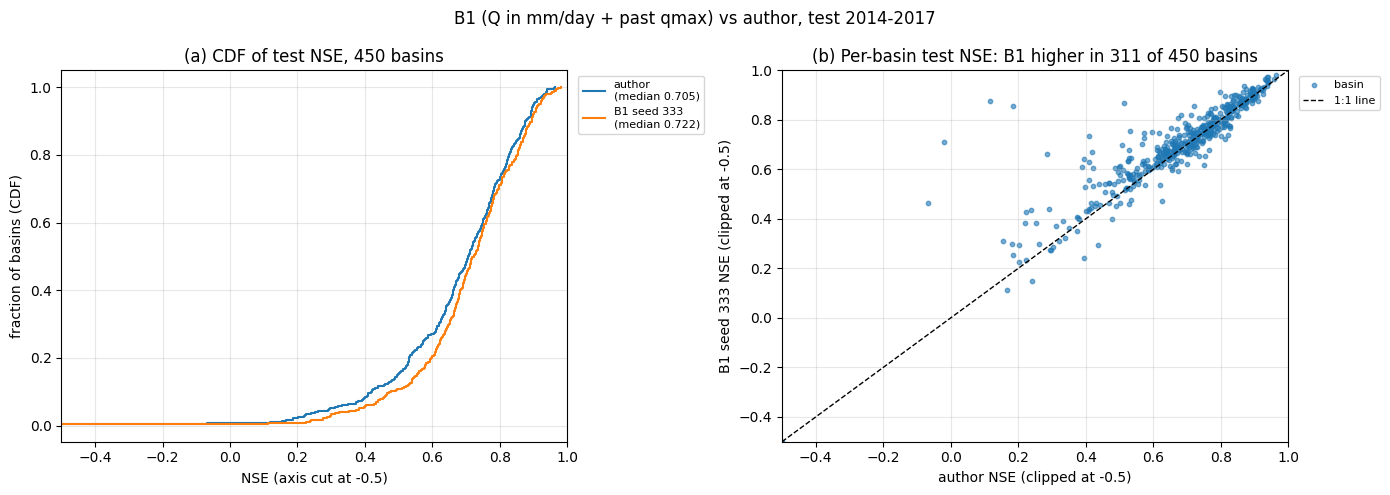

Hình: NSE test theo lưu vực của B1 hạt giống 333 so với mô hình của tác giả (cùng kiến trúc SeqLSTM có Q, Q theo m³/s, không có qmax quá khứ). (a) Phân phối: mỗi điểm trên đường là tỉ lệ lưu vực có NSE nhỏ hơn hoặc bằng giá trị ở trục ngang; đường nằm bên phải hơn là tốt hơn. (b) Mỗi chấm là một lưu vực; chấm nằm trên đường chéo là lưu vực B1 tốt hơn tác giả. Một hạt giống chưa đủ để kết luận - so với 3 hạt giống A4 ở notebook so sánh.


mục,giá trị,cần,đạt
best_model.pt trùng tensor với đúng 1 epoch,[3],1 epoch,ĐẠT
best_model.pt là epoch NSE validation cao nhất (bản sửa e794d7c),3 / 3,bằng nhau,ĐẠT
NSE validation tệp khớp log (từng epoch),8 / 8,sai lệch <= 0.0001,ĐẠT
Validation đủ 451 lưu vực mỗi epoch,[451],[451],ĐẠT
Lưu vực có NSE test (best_model.pt),450,"450 (lưu vực 55 không có dự báo, như A2, A4)",ĐẠT


=> Đạt. Chạy Phần 7.


In [6]:
# %% Phần 6 - Đánh giá test và validation, kiểm best_model.pt là epoch NSE validation cao nhất
# (1) best_model.pt là epoch nào: so từng tensor với mọi model_epochXXX.pt, phải trùng đúng một epoch. Với bản sửa e794d7c
#     (basetrainer.py: _best_metric_value riêng) epoch đó phải là epoch NSE trung vị validation cao nhất - kiểm cứng.
# (2) Đường NSE validation: trung vị NSE 451 lưu vực từng epoch từ validation/model_epochXXX/validation_metrics.csv
#     (tester.py dòng 395-412), đối chiếu số in trong log (logger.py dòng 210: np.nanmedian).
# (3) Test: eval_run(epoch="best") nạp best_model.pt (tester.py dòng 137-139), ghi test/best_model/test_metrics.csv và
#     test_results.p (khoảng 5 phút). Validation không đánh giá lại: best_model.pt trùng tensor với một epoch đã có
#     validation_results.p trên đủ 451 lưu vực (Phần 8 xuất NPZ validation từ tệp đó). NSE tác giả (0,7053) chỉ để tham
#     khảo; so chính với A4 (3 hạt giống) ở notebook so sánh.
# (4) Hình: CDF NSE test theo lưu vực và tán xạ NSE từng lưu vực, B1 so với tác giả.
# Cần chạy Phần 5 trước trong phiên (dùng RUN_DIR, TRAIN_LOG, TRAIN_HOURS, RUN_SEED, OUT_DIR, AUTHOR_TEST_NSE_MEDIAN,
# author_metrics, cfg_author, basins, show).
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
from neuralhydrology.nh_run import eval_run

LOG_TOL = 1e-4                                             # log in NSE 5 chữ số thập phân
FIG_DIR = OUT_DIR / "Figures"                              # tải về đặt ở Workspace/05_Training/01_B1_LamaHCEExt_Train/Figures/
FIG_DIR.mkdir(parents=True, exist_ok=True)
VAL_YEARS = f"{cfg_author.validation_start_date.year}-{cfg_author.validation_end_date.year}"
TEST_YEARS = f"{cfg_author.test_start_date.year}-{cfg_author.test_end_date.year}"


def epoch_of(path):
    return int(path.stem[-3:])


def same_weights(a, b):
    return a.keys() == b.keys() and all(torch.equal(a[k], b[k]) for k in a)


def caption(text):
    # Chú thích tiếng Việt in ngay dưới hình (chữ trong hình tiếng Anh).
    print(f"Hình: {text}")


def test_metrics(epoch):
    # Đánh giá test (nếu chưa có), trả DataFrame chỉ số theo lưu vực và đường dẫn tệp.
    sub = "best_model" if epoch == "best" else f"model_epoch{epoch:03d}"
    f = RUN_DIR / "test" / sub / "test_metrics.csv"
    if not f.exists():
        t0 = time.time()
        eval_run(run_dir=RUN_DIR, period="test", epoch=epoch, gpu=0)
        print(f"Đánh giá test {sub}: {(time.time() - t0) / 60:.1f} phút")
    return pd.read_csv(f, dtype={"basin": str}).set_index("basin"), f


# (1) epoch của best_model.pt
best_sd = torch.load(RUN_DIR / "best_model.pt", map_location="cpu", weights_only=True)
epoch_files = sorted(RUN_DIR.glob("model_epoch*.pt"))
match = [epoch_of(p) for p in epoch_files if same_weights(best_sd, torch.load(p, map_location="cpu", weights_only=True))]
SAVED_EPOCH = match[0] if len(match) == 1 else None

# (2) đường NSE validation theo epoch
val_rows = []
for d in sorted((RUN_DIR / "validation").glob("model_epoch*")):
    m = pd.read_csv(d / "validation_metrics.csv", dtype={"basin": str}).set_index("basin")
    val_rows.append({"epoch": epoch_of(d), "NSE trung vị validation (tệp)": float(m["NSE"].median()),
                     "số lưu vực": len(m), "lưu vực có NSE": int(m["NSE"].notna().sum())})
VAL_CURVE = pd.DataFrame(val_rows).merge(TRAIN_LOG[["epoch", "NSE trung vị validation"]].rename(
    columns={"NSE trung vị validation": "NSE trung vị validation (log)"}), on="epoch", how="left")
VAL_CURVE["khớp log"] = (VAL_CURVE["NSE trung vị validation (tệp)"] - VAL_CURVE["NSE trung vị validation (log)"]).abs() <= LOG_TOL
TRUE_BEST = int(VAL_CURVE.loc[VAL_CURVE["NSE trung vị validation (tệp)"].idxmax(), "epoch"])
VAL_CURVE["ghi chú"] = [("best_model.pt" if e == SAVED_EPOCH else "") + (" = cao nhất" if e == TRUE_BEST else "")
                        for e in VAL_CURVE["epoch"]]
VAL_CURVE.to_csv(OUT_DIR / f"validation_curve_seed{RUN_SEED}.csv", index=False)
show(f"NSE trung vị validation {VAL_YEARS} theo epoch - hạt giống {RUN_SEED}", VAL_CURVE.round(5))

# (3) test của best_model.pt
TEST_BEST, f_best = test_metrics("best")
nse_best, kge_best = float(TEST_BEST["NSE"].median()), float(TEST_BEST["KGE"].median())
n_best = int(TEST_BEST["NSE"].notna().sum())
val_nse = VAL_CURVE.set_index("epoch")["NSE trung vị validation (tệp)"]
TEST_TABLE = pd.DataFrame([
    {"mô hình": f"B1 hạt giống {RUN_SEED}, best_model.pt (epoch {SAVED_EPOCH})",
     "NSE trung vị validation": val_nse.get(SAVED_EPOCH), "NSE trung vị test": nse_best, "KGE trung vị test": kge_best,
     "lưu vực có NSE test": n_best},
    {"mô hình": "tác giả (best_model.pt, Zenodo)", "NSE trung vị validation": np.nan,
     "NSE trung vị test": AUTHOR_TEST_NSE_MEDIAN, "KGE trung vị test": float(author_metrics["KGE"].median()),
     "lưu vực có NSE test": int(author_metrics["NSE"].notna().sum())}])
TEST_TABLE["Δ NSE test so với tác giả"] = TEST_TABLE["NSE trung vị test"] - AUTHOR_TEST_NSE_MEDIAN
show(f"Test {TEST_YEARS} - hạt giống {RUN_SEED}", TEST_TABLE.round(5))

SUMMARY = {"seed": RUN_SEED, "run_dir": RUN_DIR.name, "saved_epoch": SAVED_EPOCH, "true_best_epoch": TRUE_BEST,
           "n_epochs": len(epoch_files), "val_nse_median_best_model": float(val_nse.get(SAVED_EPOCH, np.nan)),
           "test_nse_median_best_model": nse_best, "test_kge_median_best_model": kge_best,
           "author_test_nse_median": AUTHOR_TEST_NSE_MEDIAN, "train_hours": TRAIN_HOURS}
(OUT_DIR / f"summary_seed{RUN_SEED}.json").write_text(json.dumps(SUMMARY, indent=2))

# (4) Hình: chữ trong hình tiếng Anh, chú thích tiếng Việt in ngay dưới, legend đặt ngoài vùng vẽ
pair = pd.DataFrame({"author": author_metrics["NSE"], "b1": TEST_BEST["NSE"]}).dropna()
ours, theirs = pair["b1"].sort_values(), pair["author"].sort_values()
n_better = int((pair["b1"] > pair["author"]).sum())
CLIP = -0.5
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
for ser, lab in [(theirs, f"author\n(median {theirs.median():.3f})"), (ours, f"B1 seed {RUN_SEED}\n(median {ours.median():.3f})")]:
    ax1.step(ser.values, np.arange(1, len(ser) + 1) / len(ser), where="post", label=lab)
ax1.set(xlim=(CLIP, 1), xlabel="NSE (axis cut at -0.5)", ylabel="fraction of basins (CDF)",
        title=f"(a) CDF of test NSE, {len(pair)} basins")
ax2.scatter(pair["author"].clip(lower=CLIP), pair["b1"].clip(lower=CLIP), s=10, alpha=0.6, label="basin")
ax2.plot([CLIP, 1], [CLIP, 1], "k--", lw=1, label="1:1 line")
ax2.set(xlim=(CLIP, 1), ylim=(CLIP, 1), xlabel="author NSE (clipped at -0.5)",
        ylabel=f"B1 seed {RUN_SEED} NSE (clipped at -0.5)",
        title=f"(b) Per-basin test NSE: B1 higher in {n_better} of {len(pair)} basins")
for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)  # chú thích đặt ngoài vùng vẽ
fig.suptitle(f"B1 (Q in mm/day + past qmax) vs author, test {TEST_YEARS}")
fig.tight_layout()
fig.savefig(FIG_DIR / f"B1_TestNSE_Seed{RUN_SEED}.png", dpi=150, bbox_inches="tight")
plt.show()
caption(f"NSE test theo lưu vực của B1 hạt giống {RUN_SEED} so với mô hình của tác giả (cùng kiến trúc SeqLSTM có Q, Q theo "
        "m³/s, không có qmax quá khứ). (a) Phân phối: mỗi điểm trên đường là tỉ lệ lưu vực có NSE nhỏ hơn hoặc bằng giá trị ở "
        "trục ngang; đường nằm bên phải hơn là tốt hơn. (b) Mỗi chấm là một lưu vực; chấm nằm trên đường chéo là lưu vực B1 "
        "tốt hơn tác giả. Một hạt giống chưa đủ để kết luận - so với 3 hạt giống A4 ở notebook so sánh.")

checks = [("best_model.pt trùng tensor với đúng 1 epoch", match, "1 epoch", len(match) == 1),
          ("best_model.pt là epoch NSE validation cao nhất (bản sửa e794d7c)", f"{SAVED_EPOCH} / {TRUE_BEST}", "bằng nhau",
           SAVED_EPOCH == TRUE_BEST),
          ("NSE validation tệp khớp log (từng epoch)", f"{int(VAL_CURVE['khớp log'].sum())} / {len(VAL_CURVE)}",
           f"sai lệch <= {LOG_TOL}", bool(VAL_CURVE["khớp log"].all())),
          ("Validation đủ 451 lưu vực mỗi epoch", sorted(VAL_CURVE["số lưu vực"].unique().tolist()), "[451]",
           VAL_CURVE["số lưu vực"].eq(451).all()),
          ("Lưu vực có NSE test (best_model.pt)", n_best, "450 (lưu vực 55 không có dự báo, như A2, A4)", n_best == 450)]
show("Kiểm", pd.DataFrame([{"mục": a, "giá trị": str(b), "cần": c, "đạt": "ĐẠT" if d else "KHÔNG"} for a, b, c, d in checks]))
ok = all(c[3] for c in checks)
# Không raise: huấn luyện đã xong, Phần 7-8 vẫn phải chạy để lưu kết quả; dòng KHÔNG xem lại ở notebook so sánh
print("=> Đạt. Chạy Phần 7." if ok else "=> CHƯA đạt (dòng KHÔNG ở trên) - vẫn chạy Phần 7-8 để lưu kết quả, xem lại sau.")



# Phần 7 - NSE test từng epoch (chỉ theo dõi)
 Góp ý GVHD (Meeting_2026-09-27): theo dõi chỉ số tập test mỗi epoch. Chỉ để xem, không dùng chọn mô hình - mô hình vẫn là
 best_model.pt chọn theo NSE trung vị validation (03_Pipeline.md Mục 6.1). Làm sau khi huấn luyện xong, không sửa vòng
 huấn luyện: mỗi epoch có model_epochXXX.pt (save_weights_every 1).
 Một Tester kỳ test cho mọi epoch (evaluation/__init__.py get_tester). Tester chỉ tự giữ dataset khi period là validation,
 nhưng đọc lại dataset đã có trong cached_datasets ở mọi kỳ nếu cache_validation_data bật (tester.py dòng 219-230) => nạp
 sẵn dataset test của 451 lưu vực một lần (bỏ lưu vực không có dữ liệu như thư viện, dòng 224-227), mỗi epoch chỉ còn phần
 chạy mô hình. evaluate(epoch=N, save_results=True) ghi test/model_epochXXX/test_metrics.csv (tester.py dòng 388-416).
 Kiểm: NSE test của epoch best_model.pt trùng kết quả best_model.pt ở Phần 6 (cùng trọng số, cùng dữ liệu).
 Hình: (a) loss train, validation theo epoch; (b) NSE trung vị validation và test theo epoch, vạch epoch best_model.pt.
 Cần chạy Phần 6 trước trong phiên (dùng RUN_DIR, RUN_SEED, OUT_DIR, FIG_DIR, TRAIN_LOG, VAL_CURVE, SAVED_EPOCH, nse_best,
 epoch_files, epoch_of, caption, VAL_YEARS, TEST_YEARS, basins, text, show).

Nạp dataset test: 451 lưu vực, bỏ 0, 1.7 phút


Basin 55 All simulated values are NaN, thus metrics will be NaN, too.
Basin 55 All simulated values are NaN, thus metrics will be NaN, too.
Basin 55 All simulated values are NaN, thus metrics will be NaN, too.
Basin 55 All simulated values are NaN, thus metrics will be NaN, too.
Basin 55 All simulated values are NaN, thus metrics will be NaN, too.
Basin 55 All simulated values are NaN, thus metrics will be NaN, too.
Basin 55 All simulated values are NaN, thus metrics will be NaN, too.
Basin 55 All simulated values are NaN, thus metrics will be NaN, too.


epoch,loss huấn luyện,loss validation,NSE trung vị validation,NSE trung vị test,KGE trung vị test,lưu vực có NSE test,best_model.pt
1,0.013920,0.010270,0.713410,0.660580,0.632920,450,
2,0.009200,0.008810,0.753530,0.711130,0.771430,450,
3,0.008630,0.008400,0.772830,0.721650,0.777880,450,có
4,0.007910,0.008490,0.764500,0.709910,0.765540,450,
5,0.007610,0.008650,0.765050,0.721580,0.757230,450,
6,0.007340,0.008410,0.770410,0.719870,0.782790,450,
7,0.007070,0.008520,0.762190,0.717150,0.786690,450,
8,0.006840,0.008700,0.752120,0.715750,0.808430,450,


Đánh giá test: 8 epoch, trung bình 3.5 phút/epoch (cộng nạp dataset 1.7 phút)


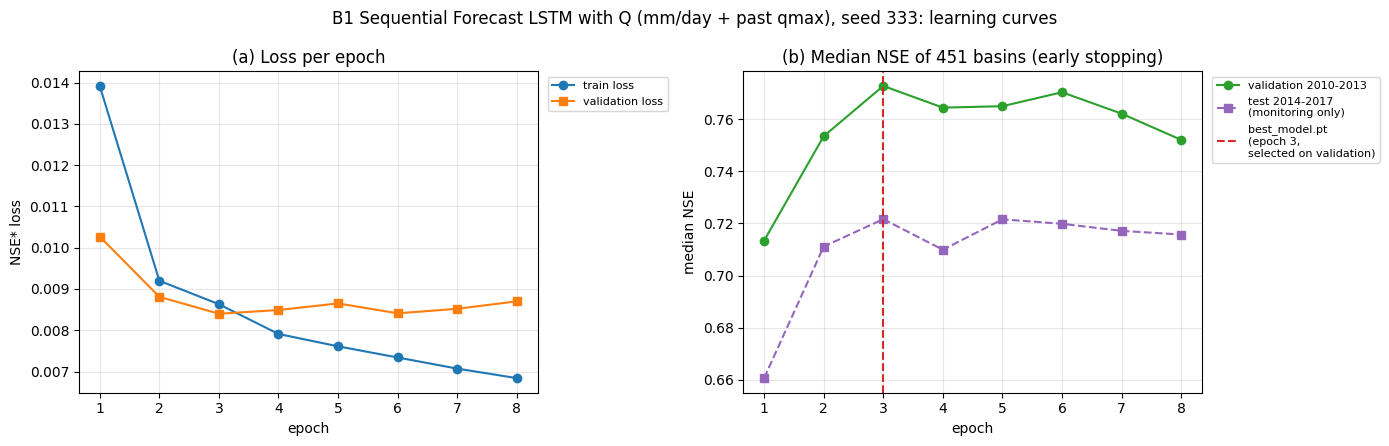

Hình: đường học của B1 hạt giống 333. (a) loss NSE* trung bình theo epoch của kỳ huấn luyện và validation - loss huấn luyện giảm còn loss validation tăng là dấu hiệu quá khớp. (b) NSE trung vị validation (dùng để chọn mô hình) và test (chỉ theo dõi, theo góp ý GVHD) theo epoch; vạch đỏ là epoch lưu thành best_model.pt. Hai đường đi cùng nhau nghĩa là chọn theo validation cũng chọn được epoch tốt trên test.


mục,giá trị,cần,đạt
Có NSE test cho mọi epoch,8 / 8,đủ,ĐẠT
NSE test epoch best_model.pt / Phần 6,0.721652 / 0.721652,lệch <= 1e-05,ĐẠT
Lưu vực có NSE test mỗi epoch,[450],[450],ĐẠT


=> Đạt. Chạy Phần 8.


In [7]:
# %% Phần 7 - NSE test từng epoch (chỉ theo dõi)
# Góp ý GVHD (Meeting_2026-09-27): theo dõi chỉ số tập test mỗi epoch. Chỉ để xem, không dùng chọn mô hình - mô hình vẫn là
# best_model.pt chọn theo NSE trung vị validation (03_Pipeline.md Mục 6.1). Làm sau khi huấn luyện xong, không sửa vòng
# huấn luyện: mỗi epoch có model_epochXXX.pt (save_weights_every 1).
# Một Tester kỳ test cho mọi epoch (evaluation/__init__.py get_tester). Tester chỉ tự giữ dataset khi period là validation,
# nhưng đọc lại dataset đã có trong cached_datasets ở mọi kỳ nếu cache_validation_data bật (tester.py dòng 219-230) => nạp
# sẵn dataset test của 451 lưu vực một lần (bỏ lưu vực không có dữ liệu như thư viện, dòng 224-227), mỗi epoch chỉ còn phần
# chạy mô hình. evaluate(epoch=N, save_results=True) ghi test/model_epochXXX/test_metrics.csv (tester.py dòng 388-416).
# Kiểm: NSE test của epoch best_model.pt trùng kết quả best_model.pt ở Phần 6 (cùng trọng số, cùng dữ liệu).
# Hình: (a) loss train, validation theo epoch; (b) NSE trung vị validation và test theo epoch, vạch epoch best_model.pt.
# Cần chạy Phần 6 trước trong phiên (dùng RUN_DIR, RUN_SEED, OUT_DIR, FIG_DIR, TRAIN_LOG, VAL_CURVE, SAVED_EPOCH, nse_best,
# epoch_files, epoch_of, caption, VAL_YEARS, TEST_YEARS, basins, text, show).
from matplotlib.ticker import MaxNLocator
from neuralhydrology.evaluation import get_tester
from neuralhydrology.utils.errors import NoEvaluationDataError

SAME_TOL = 1e-5                                            # lệch tối đa giữa NSE test epoch best_model.pt và Phần 6

# (1) Nạp sẵn dataset test một lần
t0 = time.time()
cfg_run = Config(RUN_DIR / "config.yml")
tester = get_tester(cfg=cfg_run, run_dir=RUN_DIR, period="test", init_model=True)
n_skip = 0
for b in tester.basins:
    try:
        tester.cached_datasets[b] = tester._get_dataset(b)
    except NoEvaluationDataError:
        n_skip += 1
t_load = time.time() - t0
print(f"Nạp dataset test: {len(tester.cached_datasets)} lưu vực, bỏ {n_skip}, {t_load / 60:.1f} phút")

# (2) Đánh giá test từng epoch (epoch đã có tệp thì đọc lại)
t_eval = []
test_rows = []
for p in epoch_files:
    e = epoch_of(p)
    f = RUN_DIR / "test" / f"model_epoch{e:03d}" / "test_metrics.csv"
    if not f.exists():
        t1 = time.time()
        tester.evaluate(epoch=e, save_results=True, metrics=cfg_run.metrics)
        t_eval.append(time.time() - t1)
    m = pd.read_csv(f, dtype={"basin": str}).set_index("basin")
    test_rows.append({"epoch": e, "NSE trung vị test": float(m["NSE"].median()), "KGE trung vị test": float(m["KGE"].median()),
                      "lưu vực có NSE test": int(m["NSE"].notna().sum())})
del tester
gc.collect()
loss = TRAIN_LOG[["epoch", "loss huấn luyện", "loss validation"]].replace("", np.nan).astype(float).astype({"epoch": int})
EPOCH_TABLE = (loss.merge(VAL_CURVE[["epoch", "NSE trung vị validation (tệp)"]], on="epoch", how="left")
               .rename(columns={"NSE trung vị validation (tệp)": "NSE trung vị validation"})
               .merge(pd.DataFrame(test_rows), on="epoch", how="left"))
EPOCH_TABLE["best_model.pt"] = np.where(EPOCH_TABLE["epoch"] == SAVED_EPOCH, "có", "")
EPOCH_TABLE.to_csv(OUT_DIR / f"epoch_table_seed{RUN_SEED}.csv", index=False)
show(f"Theo epoch: loss, NSE trung vị validation {VAL_YEARS} và test {TEST_YEARS} - hạt giống {RUN_SEED} "
     f"(test chỉ theo dõi)", EPOCH_TABLE.round(5))
if t_eval:
    print(f"Đánh giá test: {len(t_eval)} epoch, trung bình {np.mean(t_eval) / 60:.1f} phút/epoch "
          f"(cộng nạp dataset {t_load / 60:.1f} phút)")

# (3) Hình
stop_note = "early stopping" if "stopped early" in text else "all epochs run"
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
ax1.plot(EPOCH_TABLE["epoch"], EPOCH_TABLE["loss huấn luyện"], "o-", label="train loss")
ax1.plot(EPOCH_TABLE["epoch"], EPOCH_TABLE["loss validation"], "s-", label="validation loss")
ax1.set(xlabel="epoch", ylabel="NSE* loss", title="(a) Loss per epoch")
ax2.plot(EPOCH_TABLE["epoch"], EPOCH_TABLE["NSE trung vị validation"], "o-", color="C2", label=f"validation {VAL_YEARS}")
ax2.plot(EPOCH_TABLE["epoch"], EPOCH_TABLE["NSE trung vị test"], "s--", color="C4",
         label=f"test {TEST_YEARS}\n(monitoring only)")
if SAVED_EPOCH is not None:
    ax2.axvline(SAVED_EPOCH, color="C3", ls="--", label=f"best_model.pt\n(epoch {SAVED_EPOCH},\nselected on validation)")
ax2.set(xlabel="epoch", ylabel="median NSE", title=f"(b) Median NSE of {len(basins)} basins ({stop_note})")
for ax in (ax1, ax2):
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(alpha=0.3)
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)  # chú thích đặt ngoài vùng vẽ
fig.suptitle(f"B1 Sequential Forecast LSTM with Q (mm/day + past qmax), seed {RUN_SEED}: learning curves")
fig.tight_layout()
fig.savefig(FIG_DIR / f"B1_EpochCurve_Seed{RUN_SEED}.png", dpi=150, bbox_inches="tight")
plt.show()
caption(f"đường học của B1 hạt giống {RUN_SEED}. (a) loss NSE* trung bình theo epoch của kỳ huấn luyện và validation - loss "
        "huấn luyện giảm còn loss validation tăng là dấu hiệu quá khớp. (b) NSE trung vị validation (dùng để chọn mô hình) và "
        "test (chỉ theo dõi, theo góp ý GVHD) theo epoch; vạch đỏ là epoch lưu thành best_model.pt. Hai đường đi cùng nhau "
        "nghĩa là chọn theo validation cũng chọn được epoch tốt trên test.")

# (4) Kiểm
row_best = EPOCH_TABLE.loc[EPOCH_TABLE["epoch"] == SAVED_EPOCH]
nse_epoch_best = float(row_best["NSE trung vị test"].iloc[0]) if len(row_best) else np.nan
checks = [("Có NSE test cho mọi epoch", f"{EPOCH_TABLE['NSE trung vị test'].notna().sum()} / {len(epoch_files)}", "đủ",
           EPOCH_TABLE["NSE trung vị test"].notna().sum() == len(epoch_files)),
          ("NSE test epoch best_model.pt / Phần 6", f"{nse_epoch_best:.6f} / {nse_best:.6f}", f"lệch <= {SAME_TOL}",
           abs(nse_epoch_best - nse_best) <= SAME_TOL),
          ("Lưu vực có NSE test mỗi epoch", sorted(EPOCH_TABLE["lưu vực có NSE test"].unique().tolist()), "[450]",
           EPOCH_TABLE["lưu vực có NSE test"].eq(450).all())]
show("Kiểm", pd.DataFrame([{"mục": a, "giá trị": str(b), "cần": c, "đạt": "ĐẠT" if d else "KHÔNG"} for a, b, c, d in checks]))
# Không raise: Phần 8 vẫn phải chạy để lưu kết quả
print("=> Đạt. Chạy Phần 8." if all(c[3] for c in checks) else "=> CHƯA đạt (dòng KHÔNG ở trên) - vẫn chạy Phần 8, xem lại sau.")


# Phần 8 - Ghi môi trường, danh mục tệp, dọn thư mục dữ liệu tạm
 Output chính thức của notebook (Kaggle giữ cả /kaggle/working khi Save Version):
   b1_runs/<run>/ - config.yml, train_data/train_data_scaler.yml, model_epochXXX.pt mọi epoch, best_model.pt,
                    validation/model_epochXXX/ (chỉ số và dự báo từng epoch), test/best_model/ và test/model_epochXXX/
                    (test_metrics.csv + test_results.p, Phần 6-7), output.log;
   b1_output/     - log huấn luyện, bảng epoch, đường validation, tóm tắt, hình (Phần 5-7), environment.json, manifest.csv.
 Không xuất NPZ ở đây, như A4: hợp đồng NPZ buộc obs, persistence, diện tích trùng từng bit với ngữ cảnh A3
 (01_Evaluation_LamaHCEExt.py check_same_context) nên notebook so sánh "02_B1_LamaHCEExt_Compare" dựng NPZ test của 3 hạt
 giống từ test/best_model/test_results.p khi gắn Output A3 (cùng mã 04_A4_LamaHCEExt_Compare Phần 5). Dự báo validation
 của epoch best_model.pt (validation/model_epochXXX/validation_results.p) ghi vào manifest để dựng NPZ validation cho B* khi
 bộ đánh giá đọc được kỳ validation. Xóa thư mục dữ liệu dựng ở Phần 3 (1,53 GB, dựng lại được) để Output chỉ còn kết quả.
 Cần chạy Phần 7 trước trong phiên (dùng RUN_DIR, RUN_SEED, OUT_DIR, WORK_DIR, Q_DIR, SUMMARY, SAVED_EPOCH, EPOCH_TABLE,
 NH_COMMIT, show).

In [8]:
# %% Phần 8 - Ghi môi trường, danh mục tệp, dọn thư mục dữ liệu tạm
# Output chính thức của notebook (Kaggle giữ cả /kaggle/working khi Save Version):
#   b1_runs/<run>/ - config.yml, train_data/train_data_scaler.yml, model_epochXXX.pt mọi epoch, best_model.pt,
#                    validation/model_epochXXX/ (chỉ số và dự báo từng epoch), test/best_model/ và test/model_epochXXX/
#                    (test_metrics.csv + test_results.p, Phần 6-7), output.log;
#   b1_output/     - log huấn luyện, bảng epoch, đường validation, tóm tắt, hình (Phần 5-7), environment.json, manifest.csv.
# Không xuất NPZ ở đây, như A4: hợp đồng NPZ buộc obs, persistence, diện tích trùng từng bit với ngữ cảnh A3
# (01_Evaluation_LamaHCEExt.py check_same_context) nên notebook so sánh "02_B1_LamaHCEExt_Compare" dựng NPZ test của 3 hạt
# giống từ test/best_model/test_results.p khi gắn Output A3 (cùng mã 04_A4_LamaHCEExt_Compare Phần 5). Dự báo validation
# của epoch best_model.pt (validation/model_epochXXX/validation_results.p) ghi vào manifest để dựng NPZ validation cho B* khi
# bộ đánh giá đọc được kỳ validation. Xóa thư mục dữ liệu dựng ở Phần 3 (1,53 GB, dựng lại được) để Output chỉ còn kết quả.
# Cần chạy Phần 7 trước trong phiên (dùng RUN_DIR, RUN_SEED, OUT_DIR, WORK_DIR, Q_DIR, SUMMARY, SAVED_EPOCH, EPOCH_TABLE,
# NH_COMMIT, show).
import hashlib
import platform
from importlib import metadata

ENV_LIBS = ["neuralhydrology", "torch", "numpy", "pandas", "xarray", "scipy", "numba", "ruamel.yaml"]
KEY_FILES = ["config.yml", "train_data/train_data_scaler.yml", "best_model.pt", "test/best_model/test_metrics.csv",
             "test/best_model/test_results.p", "output.log"]
if SAVED_EPOCH is not None:
    KEY_FILES += [f"validation/model_epoch{SAVED_EPOCH:03d}/validation_metrics.csv",
                  f"validation/model_epoch{SAVED_EPOCH:03d}/validation_results.p"]


def sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as fp:
        for chunk in iter(lambda: fp.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


# (1) Môi trường
try:
    nh_commit = json.loads(metadata.distribution("neuralhydrology").read_text("direct_url.json"))["vcs_info"]["commit_id"]
except Exception:  # cài không qua git => không có direct_url.json
    nh_commit = "không rõ"
SUMMARY["test_nse_median_per_epoch"] = {int(r.epoch): float(r["NSE trung vị test"]) for _, r in EPOCH_TABLE.iterrows()}
env = {"seed": RUN_SEED, "run_dir": RUN_DIR.relative_to(WORK_DIR).as_posix(), "python": sys.version.split()[0],
       "platform": platform.platform(), "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
       "neuralhydrology_commit": nh_commit, "neuralhydrology_commit_expected": NH_COMMIT,
       "config_sha256": sha256(RUN_DIR / "config.yml"), "libs": {lib: metadata.version(lib) for lib in ENV_LIBS},
       "summary": SUMMARY,
       "q_dir_note": "LamaH_q_mmd_input dựng bằng Phần 3 (qmean_mmd, qmax_mmd mm/ngày theo area_gov từ D_gauges, "
                     "số âm => trống), đã xóa khỏi Output"}
(OUT_DIR / "environment.json").write_text(json.dumps(env, ensure_ascii=False, indent=2), encoding="utf-8")

# (2) Danh mục tệp chính kèm sha256 (notebook so sánh kiểm lại khi đọc)
man = [{"tệp": (RUN_DIR / rel).relative_to(WORK_DIR).as_posix(), "KB": round((RUN_DIR / rel).stat().st_size / 1e3, 1),
        "sha256": sha256(RUN_DIR / rel)} for rel in KEY_FILES if (RUN_DIR / rel).exists()]
missing = [rel for rel in KEY_FILES if not (RUN_DIR / rel).exists()]
MANIFEST = pd.DataFrame(man)
MANIFEST.to_csv(OUT_DIR / "manifest.csv", index=False)
show("Tệp chính của run (manifest.csv)", MANIFEST.assign(sha256=MANIFEST["sha256"].str[:12] + "..."))

# (3) Dọn thư mục dữ liệu tạm, đo dung lượng Output
if Q_DIR.exists():
    shutil.rmtree(Q_DIR)  # chỉ xóa tệp đã dựng và liên kết; rmtree không đi theo liên kết tới dữ liệu gốc


def du_gb(path):
    return sum(f.stat().st_size for f in Path(path).rglob("*") if f.is_file() and not f.is_symlink()) / 1e9


sizes = [{"thư mục": d.name, "GB": round(du_gb(d), 3)} for d in sorted(WORK_DIR.iterdir()) if d.is_dir()]
show("Dung lượng /kaggle/working (Output của bản lưu)", pd.DataFrame(sizes))

checks = [("Đủ tệp chính trong thư mục run", f"{len(man)} / {len(KEY_FILES)}", "đủ", not missing),
          ("Commit thư viện đúng e794d7c", nh_commit[:7], NH_COMMIT[:7], nh_commit == NH_COMMIT),
          ("Đã xóa thư mục dữ liệu tạm", not Q_DIR.exists(), "True", not Q_DIR.exists()),
          ("Tổng Output", f"{sum(r['GB'] for r in sizes):.2f} GB", "<= 20 GB", sum(r["GB"] for r in sizes) <= 20)]
show("Kiểm", pd.DataFrame([{"mục": a, "giá trị": str(b), "cần": c, "đạt": "ĐẠT" if d else "KHÔNG"} for a, b, c, d in checks]))
if missing:
    print("Thiếu:", missing)
print("=> Đạt. Xong notebook." if all(c[3] for c in checks) else "=> CHƯA đạt (dòng KHÔNG ở trên): gửi output này.")


tệp,KB,sha256
b1_runs/B1_SeqLSTM_Q_seed333_2410_170509/config.yml,3.800000,c2794fad7b8c...
b1_runs/B1_SeqLSTM_Q_seed333_2410_170509/train_data/train_data_scaler.yml,8.600000,baae107de375...
b1_runs/B1_SeqLSTM_Q_seed333_2410_170509/best_model.pt,345.300000,bda19969a8ce...
b1_runs/B1_SeqLSTM_Q_seed333_2410_170509/test/best_model/test_metrics.csv,18.800000,539047c13c6a...
b1_runs/B1_SeqLSTM_Q_seed333_2410_170509/test/best_model/test_results.p,16177.800000,6fcf105db18d...
b1_runs/B1_SeqLSTM_Q_seed333_2410_170509/output.log,12.100000,2426331dee47...
b1_runs/B1_SeqLSTM_Q_seed333_2410_170509/validation/model_epoch003/validation_metrics.csv,18.800000,435c37e2fe60...
b1_runs/B1_SeqLSTM_Q_seed333_2410_170509/validation/model_epoch003/validation_results.p,16177.800000,8d874428eb1c...


thư mục,GB
b1_configs,0.000000
b1_output,0.000000
b1_runs,0.285000


mục,giá trị,cần,đạt
Đủ tệp chính trong thư mục run,8 / 8,đủ,ĐẠT
Commit thư viện đúng e794d7c,e794d7c,e794d7c,ĐẠT
Đã xóa thư mục dữ liệu tạm,True,True,ĐẠT
Tổng Output,0.28 GB,<= 20 GB,ĐẠT


=> Đạt. Xong notebook.
